In [4]:

cran_pkgs <- c("httr", "rvest", "xml2",
               "tm", "SnowballC", "lda",
               "ggplot2", "reshape2", "wordcloud", "RColorBrewer")

to_install <- cran_pkgs[!cran_pkgs %in% rownames(installed.packages())]
if (length(to_install) > 0) {
  cat("Installing:", paste(to_install, collapse = ", "), "\n")
  install.packages(to_install, quiet = TRUE)
}

suppressPackageStartupMessages({
  library(httr); library(rvest); library(xml2)
  library(tm); library(SnowballC); library(lda)
  library(ggplot2); library(reshape2); library(wordcloud); library(RColorBrewer)
})
cat("Loaded:", paste(cran_pkgs, collapse = ", "), "\n")

Loaded: httr, rvest, xml2, tm, SnowballC, lda, ggplot2, reshape2, wordcloud, RColorBrewer 


In [5]:
# ---- 0.2  Java + Hadoop (Q1) and PostgreSQL (Q4) ----
java_home   <- "/usr/lib/jvm/java-11-openjdk-amd64"
hadoop_ver  <- "3.3.6"
hadoop_home <- file.path("/content", paste0("hadoop-", hadoop_ver))

# apt packages we still need
need_apt <- c(if (!dir.exists(java_home)) "openjdk-11-jdk-headless",
              if (Sys.which("psql") == "") "postgresql")
if (length(need_apt) > 0) {
  cat("Installing", paste(need_apt, collapse = " + "), "- this takes a minute or two...\n")
  system("apt-get -qq update > /dev/null 2>&1")
  system(paste("DEBIAN_FRONTEND=noninteractive apt-get -qq install -y",
               paste(need_apt, collapse = " "), "> /dev/null 2>&1"))
}

# Hadoop: try the fast mirror first, then the Apache archive
if (!file.exists(file.path(hadoop_home, "bin/hadoop"))) {
  tgz <- "/content/hadoop.tar.gz"
  mirrors <- sprintf(c("https://dlcdn.apache.org/hadoop/common/hadoop-%s/hadoop-%s.tar.gz",
                       "https://archive.apache.org/dist/hadoop/common/hadoop-%s/hadoop-%s.tar.gz"),
                     hadoop_ver, hadoop_ver)
  for (u in mirrors) {
    cat("Downloading Hadoop from", u, "\n")
    ok <- system(paste("wget -q -O", tgz, u)) == 0
    if (ok && file.exists(tgz) && file.size(tgz) > 1e8) break
  }
  if (file.exists(tgz) && file.size(tgz) > 1e8) system(paste("tar -xzf", tgz, "-C /content"))
  unlink(tgz)
}

HADOOP_READY <- dir.exists(java_home) && file.exists(file.path(hadoop_home, "bin/hadoop"))
if (HADOOP_READY) {
  Sys.setenv(JAVA_HOME       = java_home,
             HADOOP_HOME     = hadoop_home,
             HADOOP_CONF_DIR = file.path(hadoop_home, "etc/hadoop"),
             PATH            = paste(file.path(hadoop_home, "bin"), Sys.getenv("PATH"), sep = ":"))
}

# PostgreSQL: start the server and check we can talk to it
system("service postgresql start > /dev/null 2>&1")
Sys.sleep(3)
PG_READY <- system("su postgres -c \"psql -tAc 'SELECT 1'\" > /dev/null 2>&1") == 0

cat("\nJava + Hadoop ready:", HADOOP_READY, "\nPostgreSQL ready:   ", PG_READY, "\n")


Java + Hadoop ready: TRUE 
PostgreSQL ready:    TRUE 


### 0.3 Data files

In [6]:
# ---- 0.3  Locate and unzip the data files (once) ----
find_zip <- function(pattern, what) {
  z <- list.files("/content", pattern = pattern, ignore.case = TRUE, full.names = TRUE)
  z <- z[grepl("\\.zip$", z, ignore.case = TRUE)]
  if (length(z) == 0)
    stop("Can't find the ", what, " zip in /content. Upload it in the Files panel and run this cell again.")
  z[1]
}
unzip_txt <- function(zip_path, dest) {
  unlink(dest, recursive = TRUE)
  unzip(zip_path, exdir = dest)
  unlink(file.path(dest, "__MACOSX"), recursive = TRUE)        # junk folder from Mac zips
  f <- list.files(dest, pattern = "\\.txt$", full.names = TRUE, recursive = TRUE)
  f[!grepl("__MACOSX|/\\._", f)]
}

MR_ZIP   <- find_zip("map.?reduce", "MapReduce test documents (map_reduce_test_docs.zip)")
NEWS_ZIP <- find_zip("news",        "news articles (news.zip)")

MR_DOCS    <- unzip_txt(MR_ZIP,   "/content/data/mapreduce")
MR_DIR     <- dirname(MR_DOCS[1])                               # folder Hadoop reads from
NEWS_FILES <- unzip_txt(NEWS_ZIP, "/content/data/news")
NEWS_FILES <- NEWS_FILES[order(as.numeric(gsub("\\D", "", basename(NEWS_FILES))))]   # news_1 ... news_10

# one output folder per question
OUT <- "/content/outputs"
for (d in file.path(OUT, c("q1", "q2", "q3", "q4"))) dir.create(d, recursive = TRUE, showWarnings = FALSE)

cat("Q1 MapReduce docs:", length(MR_DOCS), "files ->", paste(basename(MR_DOCS), collapse = ", "), "\n")
cat("Q2 news articles: ", length(NEWS_FILES), "files ->", paste(basename(NEWS_FILES), collapse = ", "), "\n")
cat("Outputs will be saved under", OUT, "\n")

Q1 MapReduce docs: 7 files -> doc1.txt, doc2.txt, doc3.txt, doc4.txt, doc5.txt, doc6.txt, doc7.txt 
Q2 news articles:  10 files -> news_1.txt, news_2.txt, news_3.txt, news_4.txt, news_5.txt, news_6.txt, news_7.txt, news_8.txt, news_9.txt, news_10.txt 
Outputs will be saved under /content/outputs 


### 0.4 Settings




In [7]:

KEYWORD <- "africa"

# Q2:
N_TOPICS <- 5
K_WORDS  <- 10

# Q3:
WEB_URL   <- "https://en.wikipedia.org/wiki/Natural_language_processing"
N_SUMMARY <- 5     # sentences per summary

# Q3 + Q4:
CONTACT_EMAIL <- "your.email@example.com"

# Q4.4: set to TRUE only if you want the notebook to push the repo to GitHub for you
PUSH_TO_GITHUB <- FALSE

cat("\nKeyword:", KEYWORD, "| topics:", N_TOPICS, "| words per topic:", K_WORDS,
    "| summary sentences:", N_SUMMARY, "\nWeb link:", WEB_URL, "\n")


Keyword: africa | topics: 5 | words per topic: 10 | summary sentences: 5 
Web link: https://en.wikipedia.org/wiki/Natural_language_processing 



## Question 1

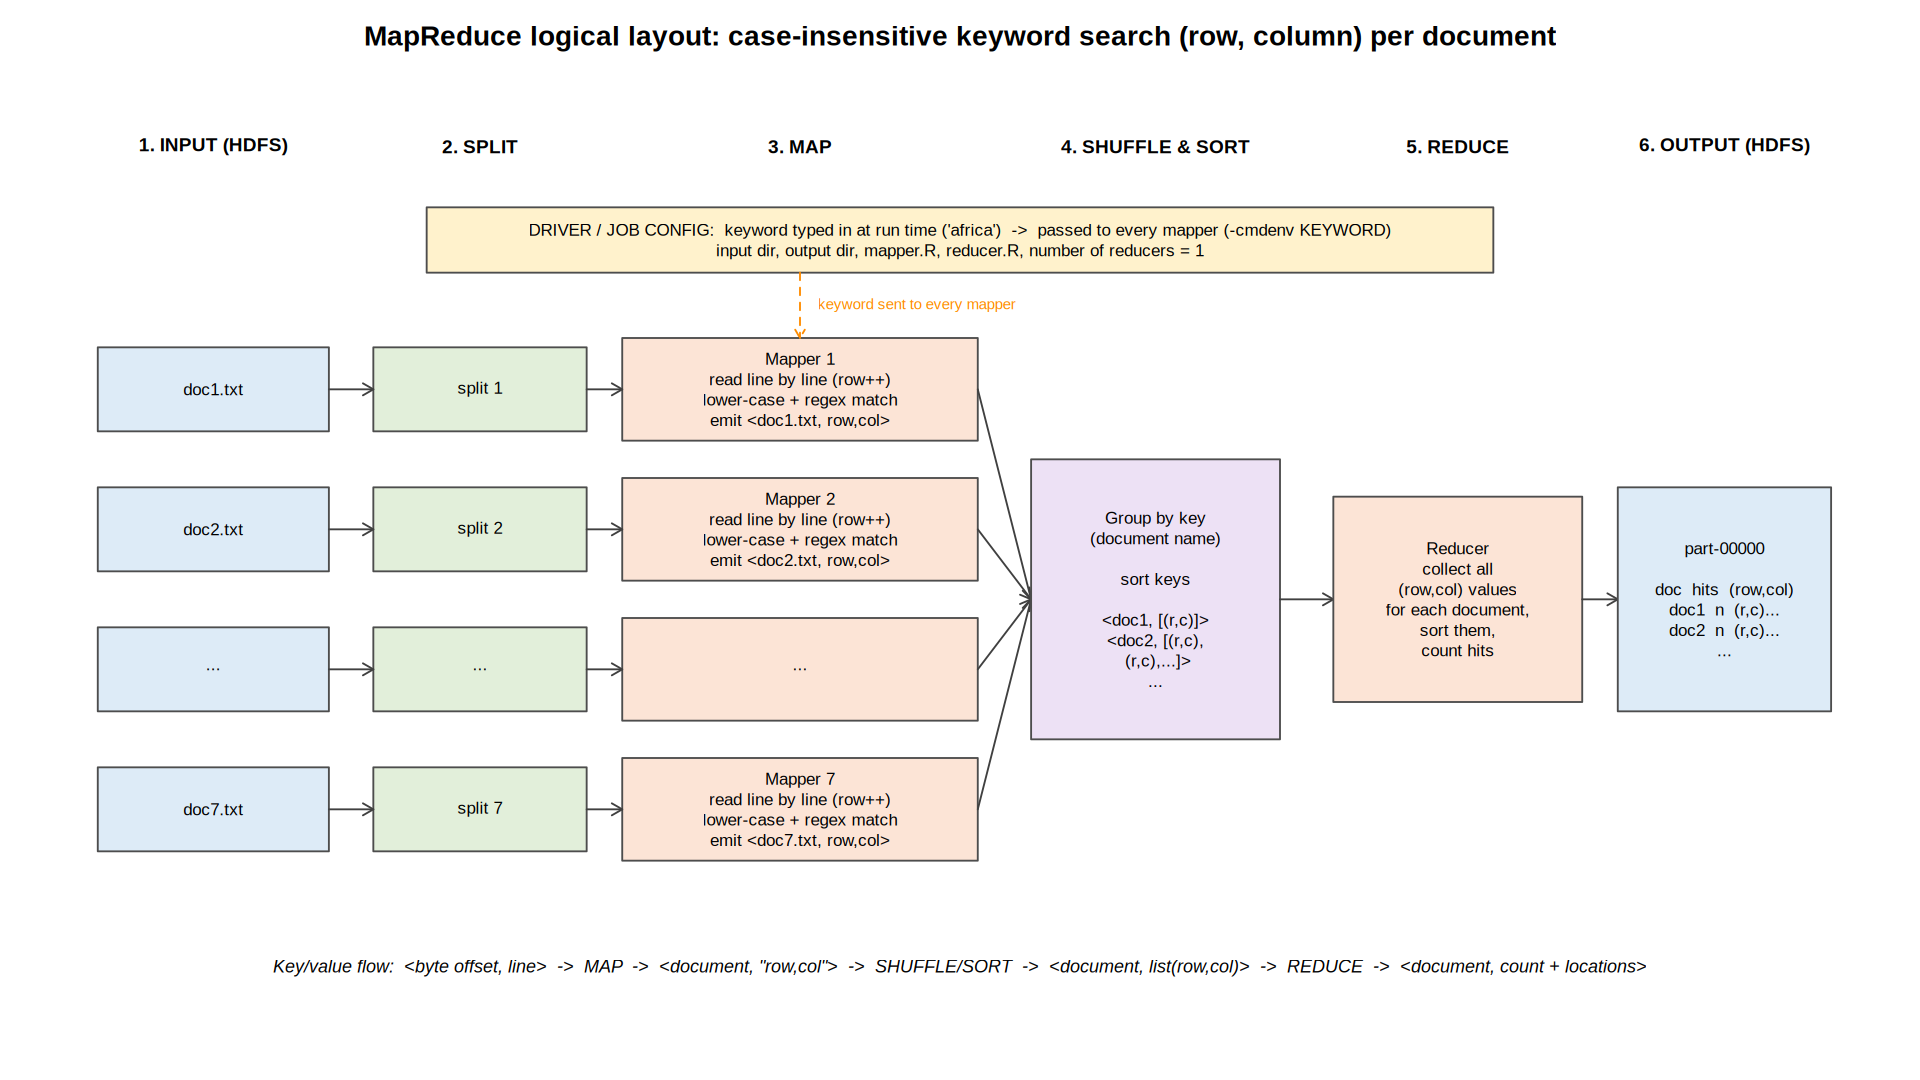

In [8]:
# ---- 1.1  Logical layout diagram ----
options(repr.plot.width = 16, repr.plot.height = 9)
par(mar = c(0, 0, 3, 0))
plot(NULL, xlim = c(0, 100), ylim = c(0, 100), axes = FALSE, xlab = "", ylab = "",
     main = "MapReduce logical layout: case-insensitive keyword search (row, column) per document",
     cex.main = 1.4)

draw_box <- function(x, y, w, h, label, fill) {
  rect(x - w/2, y - h/2, x + w/2, y + h/2, col = fill, border = "grey30", lwd = 1.5)
  text(x, y, label, cex = 0.85)
}
draw_arrow <- function(x0, y0, x1, y1) arrows(x0, y0, x1, y1, length = 0.1, lwd = 1.5, col = "grey25")

text(c(8, 23, 41, 61, 78, 93), 96, font = 2, cex = 0.95,
     c("1. INPUT (HDFS)", "2. SPLIT", "3. MAP", "4. SHUFFLE & SORT", "5. REDUCE", "6. OUTPUT (HDFS)"))

draw_box(50, 86, 60, 7, paste0("DRIVER / JOB CONFIG:  keyword typed in at run time ('", KEYWORD,
         "')  ->  passed to every mapper (-cmdenv KEYWORD)\ninput dir, output dir, mapper.R, reducer.R, number of reducers = 1"),
         "#FFF2CC")

ys         <- c(70, 55, 40, 25)
doc_labels <- c("doc1.txt", "doc2.txt", "...", "doc7.txt")
split_no   <- c(1, 2, NA, 7)
for (i in 1:4) {
  is_gap <- doc_labels[i] == "..."
  draw_box(8,  ys[i], 13, 9, doc_labels[i], "#DDEBF7")
  draw_box(23, ys[i], 12, 9, if (is_gap) "..." else paste("split", split_no[i]), "#E2EFDA")
  draw_box(41, ys[i], 20, 11, if (is_gap) "..." else
             paste0("Mapper ", split_no[i], "\nread line by line (row++)\nlower-case + regex match\nemit <",
                    doc_labels[i], ", row,col>"), "#FCE4D6")
  draw_arrow(14.5, ys[i], 17, ys[i]); draw_arrow(29, ys[i], 31, ys[i]); draw_arrow(51, ys[i], 54, 47.5)
}
arrows(41, 82.5, 41, ys[1] + 5.5, length = 0.08, lty = 2, col = "darkorange", lwd = 1.5)
text(42, 79, "keyword sent to every mapper", adj = 0, cex = 0.75, col = "darkorange")

draw_box(61, 47.5, 14, 30, "Group by key\n(document name)\n\nsort keys\n\n<doc1, [(r,c)]>\n<doc2, [(r,c),\n (r,c),...]>\n...", "#EDE1F5")
draw_arrow(68, 47.5, 71, 47.5)
draw_box(78, 47.5, 14, 22, "Reducer\ncollect all\n(row,col) values\nfor each document,\nsort them,\ncount hits", "#FCE4D6")
draw_arrow(85, 47.5, 87, 47.5)
draw_box(93, 47.5, 12, 24, "part-00000\n\ndoc  hits  (row,col)\ndoc1  n  (r,c)...\ndoc2  n  (r,c)...\n...", "#DDEBF7")

text(50, 8, cex = 0.9, font = 3,
     "Key/value flow:  <byte offset, line>  ->  MAP  ->  <document, \"row,col\">  ->  SHUFFLE/SORT  ->  <document, list(row,col)>  ->  REDUCE  ->  <document, count + locations>")

### 1.2 Mapper

In [9]:

Q1_DIR <- file.path(OUT, "q1")
mapper_path <- file.path(Q1_DIR, "mapper.R")

mapper_code <- r"---(#!/usr/bin/env Rscript
# mapper.R
# Input : lines of ONE document on stdin (one input split = one document)
# Output: <document \t row,column> for every occurrence of the keyword

# keyword comes from the command line or from the KEYWORD env variable (-cmdenv)
args    <- commandArgs(trailingOnly = TRUE)
keyword <- if (length(args) >= 1) args[1] else Sys.getenv("KEYWORD")
if (!nzchar(keyword)) stop("mapper.R: no keyword supplied")
keyword <- tolower(trimws(keyword))

# Hadoop Streaming exposes the file being processed as an environment variable
doc <- Sys.getenv("mapreduce_map_input_file", Sys.getenv("map_input_file", "unknown_doc"))
doc <- basename(doc)

# escape regex special characters, then match the keyword as a whole word
kw_escaped <- gsub("([][{}()+*^$|\\\\?.])", "\\\\\\1", keyword)
pattern    <- paste0("(?<![[:alnum:]])", kw_escaped, "(?![[:alnum:]])")

con <- file("stdin", open = "r")
row <- 0
while (length(line <- readLines(con, n = 1, warn = FALSE, encoding = "UTF-8")) > 0) {
  row  <- row + 1                                     # row = line number in the document
  hits <- gregexpr(pattern, line, ignore.case = TRUE, perl = TRUE)[[1]]   # case-insensitive
  if (hits[1] != -1) {
    for (col in hits) {                               # col = character position in the line
      cat(doc, "\t", row, ",", col, "\n", sep = "")   # emit <key, value>
    }
  }
}
close(con)
)---"
writeLines(mapper_code, mapper_path)
Sys.chmod(mapper_path, mode = "0755")
cat("mapper.R saved to", mapper_path, "\n")

# Demonstration: one map task per document
map_out <- file.path(Q1_DIR, "map_output.txt")
unlink(map_out)
for (d in MR_DOCS) {
  system(sprintf("mapreduce_map_input_file=%s Rscript %s %s < %s >> %s",
                 shQuote(d), mapper_path, shQuote(KEYWORD), shQuote(d), map_out))
}

map_pairs <- if (file.exists(map_out) && file.size(map_out) > 0)
  read.delim(map_out, header = FALSE, col.names = c("key", "value"), colClasses = "character") else
  data.frame(key = character(0), value = character(0))
cat("\nIntermediate <key, value> pairs emitted by the mappers for '", KEYWORD, "':\n", sep = "")
print(map_pairs, row.names = FALSE)
cat("\nTotal pairs emitted:", nrow(map_pairs), "\n")

# Proof the keyword is a run-time input: the SAME mapper, a different keyword
other_keyword <- "south"
other_hits <- unlist(lapply(MR_DOCS, function(d)
  system(sprintf("mapreduce_map_input_file=%s Rscript %s %s < %s",
                 shQuote(d), mapper_path, shQuote(other_keyword), shQuote(d)), intern = TRUE)))
cat("\nSame mapper.R run with the keyword '", other_keyword, "': ", length(other_hits),
    " pairs emitted, e.g. ", paste(head(other_hits, 3), collapse = " | "), "\n", sep = "")

mapper.R saved to /content/outputs/q1/mapper.R 

Intermediate <key, value> pairs emitted by the mappers for 'africa':
      key  value
 doc1.txt   1,64
 doc2.txt   1,57
 doc2.txt  33,24
 doc2.txt  58,81
 doc3.txt   1,38
 doc3.txt    3,7
 doc3.txt    5,7
 doc3.txt 40,146
 doc3.txt   46,7
 doc3.txt 50,142
 doc3.txt  52,86
 doc3.txt  54,44
 doc5.txt   1,62
 doc5.txt   3,88
 doc5.txt 23,121
 doc5.txt  38,27

Total pairs emitted: 16 

Same mapper.R run with the keyword 'south': 22 pairs emitted, e.g. doc1.txt	1,58 | doc1.txt	3,5 | doc1.txt	3,89


### 1.3 Reducer

In [10]:

reducer_path <- file.path(Q1_DIR, "reducer.R")

reducer_code <- r"---(#!/usr/bin/env Rscript
# reducer.R
# Input : sorted <document \t row,column> pairs on stdin (from shuffle & sort)
# Output: <document \t number_of_hits \t (row,col) (row,col) ...>

con <- file("stdin", open = "r")
current_doc <- NULL
positions   <- character(0)

emit <- function(doc, pos) {
  rc  <- do.call(rbind, strsplit(pos, ","))
  ord <- order(as.integer(rc[, 1]), as.integer(rc[, 2]))   # sort by row, then column
  out <- paste0("(", rc[ord, 1], ",", rc[ord, 2], ")", collapse = " ")
  cat(doc, "\t", length(pos), "\t", out, "\n", sep = "")
}

while (length(line <- readLines(con, n = 1, warn = FALSE)) > 0) {
  if (!nzchar(line)) next
  parts <- strsplit(line, "\t", fixed = TRUE)[[1]]
  doc <- parts[1]; pos <- trimws(parts[2])
  if (!is.null(current_doc) && doc != current_doc) {        # key changed -> flush
    emit(current_doc, positions)
    positions <- character(0)
  }
  current_doc <- doc
  positions   <- c(positions, pos)
}
if (!is.null(current_doc)) emit(current_doc, positions)     # last key
close(con)
)---"
writeLines(reducer_code, reducer_path)
Sys.chmod(reducer_path, mode = "0755")
cat("reducer.R saved to", reducer_path, "\n\n")

# shuffle & sort by key, then reduce
sorted_out <- file.path(Q1_DIR, "sorted_output.txt")
final_out  <- file.path(Q1_DIR, "final_output.txt")
system(sprintf("LC_ALL=C sort -k1,1 %s > %s", map_out, sorted_out))
system(sprintf("Rscript %s < %s > %s", reducer_path, sorted_out, final_out))

final <- if (file.size(final_out) > 0)
  read.delim(final_out, header = FALSE, col.names = c("document", "hits", "row_col_locations"),
             colClasses = "character") else data.frame()

if (nrow(final) == 0) {
  cat("No occurrences of '", KEYWORD, "' were found in any document.\n", sep = "")
} else {
  cat("FINAL MapReduce output for '", KEYWORD, "' (document | hits | (row,column) locations):\n\n", sep = "")
  for (i in seq_len(nrow(final)))
    cat(final$document[i], " -> ", final$hits[i], " hit(s)\n   ", final$row_col_locations[i], "\n\n", sep = "")
  cat("Total hits:", sum(as.integer(final$hits)), "in", nrow(final), "of", length(MR_DOCS), "documents\n")

  # sanity check: read the text at the first reported location
  first_loc <- strsplit(final$row_col_locations[1], " ")[[1]][1]
  rc  <- as.integer(strsplit(gsub("[()]", "", first_loc), ",")[[1]])
  txt <- readLines(file.path(MR_DIR, final$document[1]), warn = FALSE, encoding = "UTF-8")[rc[1]]
  cat("Check:", final$document[1], "row", rc[1], "col", rc[2], "reads ->",
      substr(txt, rc[2], rc[2] + nchar(KEYWORD) - 1), "\n")
}

reducer.R saved to /content/outputs/q1/reducer.R 

FINAL MapReduce output for 'africa' (document | hits | (row,column) locations):

doc1.txt -> 1 hit(s)
   (1,64)

doc2.txt -> 3 hit(s)
   (1,57) (33,24) (58,81)

doc3.txt -> 8 hit(s)
   (1,38) (3,7) (5,7) (40,146) (46,7) (50,142) (52,86) (54,44)

doc5.txt -> 4 hit(s)
   (1,62) (3,88) (23,121) (38,27)

Total hits: 16 in 4 of 7 documents
Check: doc1.txt row 1 col 64 reads -> Africa 


### 1.4

In [11]:

if (!HADOOP_READY) {
  cat("Hadoop isn't available (the download in 0.2 didn't finish), so the real Hadoop run is skipped.\n",
      "Re-run cell 0.2 and then this cell. The MapReduce result from 1.2-1.3 above is still valid.\n")
} else {
  conf_dir <- Sys.getenv("HADOOP_CONF_DIR")

  # hadoop-env.sh: tell Hadoop where Java is (only added once)
  env_file <- file.path(conf_dir, "hadoop-env.sh")
  if (!any(grepl(java_home, readLines(env_file), fixed = TRUE)))
    write(paste0("export JAVA_HOME=", java_home), env_file, append = TRUE)

  prop <- function(name, value)
    sprintf("  <property>\n    <name>%s</name>\n    <value>%s</value>\n  </property>", name, value)
  write_conf <- function(file, props)
    writeLines(c('<?xml version="1.0"?>', "<configuration>", props, "</configuration>"), file.path(conf_dir, file))

  write_conf("core-site.xml", c(
    prop("fs.defaultFS",   "file:///"),
    prop("hadoop.tmp.dir", "/content/hadoop_tmp")))
  write_conf("hdfs-site.xml", c(
    prop("dfs.replication", "1"),
    prop("dfs.blocksize",   "134217728")))
  write_conf("mapred-site.xml", c(
    prop("mapreduce.framework.name", "local"),
    prop("mapreduce.job.reduces",    "1"),
    prop("mapreduce.input.fileinputformat.split.minsize", "268435456")))

  for (f in c("core-site.xml", "hdfs-site.xml", "mapred-site.xml")) {
    cat("", f, "\n"); cat(readLines(file.path(conf_dir, f)), sep = "\n"); cat("\n")
  }

  streaming_jar <- Sys.glob(file.path(hadoop_home, "share/hadoop/tools/lib/hadoop-streaming-*.jar"))[1]
  hadoop_out    <- file.path(Q1_DIR, "hadoop_output")
  unlink(hadoop_out, recursive = TRUE)

  job <- paste(
    "hadoop jar", streaming_jar,
    "-D mapreduce.job.name=KeywordSearch",
    "-D mapreduce.job.reduces=1",
    "-cmdenv", shQuote(paste0("KEYWORD=", KEYWORD)),
    "-input",  shQuote(MR_DIR),
    "-output", shQuote(hadoop_out),
    "-mapper",  shQuote(paste("Rscript", mapper_path)),
    "-reducer", shQuote(paste("Rscript", reducer_path)),
    "2>&1")
  cat("Submitting job:\n", job, "\n\n")
  job_log <- suppressWarnings(system(job, intern = TRUE))
  cat(grep("Running job|completed successfully|Map input records|Map output records|Reduce output records|ERROR|Exception",
           job_log, value = TRUE), sep = "\n")

  part_file <- file.path(hadoop_out, "part-00000")
  if (file.exists(part_file)) {
    cat("\n Hadoop output: part-00000 (document | hits | (row,column)) \n")
    cat(readLines(part_file), sep = "\n")
    cat("\nSame result as the 1.2-1.3 pipeline?", identical(readLines(part_file), readLines(final_out)), "\n")
  } else {
    cat("\nThe Hadoop job did not produce output. Last lines of the log:\n")
    cat(tail(job_log, 15), sep = "\n")
  }
}

 core-site.xml 
<?xml version="1.0"?>
<configuration>
  <property>
    <name>fs.defaultFS</name>
    <value>file:///</value>
  </property>
  <property>
    <name>hadoop.tmp.dir</name>
    <value>/content/hadoop_tmp</value>
  </property>
</configuration>

 hdfs-site.xml 
<?xml version="1.0"?>
<configuration>
  <property>
    <name>dfs.replication</name>
    <value>1</value>
  </property>
  <property>
    <name>dfs.blocksize</name>
    <value>134217728</value>
  </property>
</configuration>

 mapred-site.xml 
<?xml version="1.0"?>
<configuration>
  <property>
    <name>mapreduce.framework.name</name>
    <value>local</value>
  </property>
  <property>
    <name>mapreduce.job.reduces</name>
    <value>1</value>
  </property>
  <property>
    <name>mapreduce.input.fileinputformat.split.minsize</name>
    <value>268435456</value>
  </property>
</configuration>

Submitting job:
 hadoop jar /content/hadoop-3.3.6/share/hadoop/tools/lib/hadoop-streaming-3.3.6.jar -D mapreduce.job.name=KeywordSe


## Question 2

Question2.1

In [12]:

news_df <- data.frame(
  file_name = basename(NEWS_FILES),
  content   = sapply(NEWS_FILES, function(f) paste(readLines(f, warn = FALSE, encoding = "UTF-8"), collapse = " ")),
  stringsAsFactors = FALSE, row.names = NULL)
cat("Rows (articles):", nrow(news_df), "\n\n")
print(data.frame(file_name = news_df$file_name,
                 content   = paste0(substr(news_df$content, 1, 55), "...")), right = FALSE)

news_stopwords <- c("said", "says", "also", "will", "can", "one", "two", "may", "must", "well",
                    "mr", "ms", "sanews", "gov", "minister", "department", "according", "year", "years",
                    "however", "including", "would", "make", "made", "take", "like", "just",
                    "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday",
                    "january", "february", "march", "april", "june", "july", "august",
                    "september", "october", "november", "december")

clean_news <- function(x) {
  x <- gsub("[\\x{2018}\\x{2019}\\x{201A}\\x{2032}]", "'", x, perl = TRUE)  # curly apostrophes -> '
  x <- gsub("[\\x{201C}\\x{201D}\\x{201E}]", " ", x, perl = TRUE)          # curly double quotes
  x <- gsub("[\\x{2013}\\x{2014}]", " ", x, perl = TRUE)                    # en/em dashes
  x <- gsub("(https?://|www\\.)\\S+", " ", x)                               # URLs
  x <- gsub("\\S+@\\S+", " ", x)                                            # e-mail addresses
  x <- tolower(x)                                                           # case folding
  x <- gsub("'s\\b", " ", x)                                                # possessives
  x <- gsub("[^a-z ]", " ", x)                                              # numbers, punctuation, symbols
  x <- removeWords(x, stopwords("english"))                                 # Snowball stop words
  x <- removeWords(x, news_stopwords)                                       # news filler words
  x <- gsub("\\b[a-z]{1,2}\\b", " ", x)                                     # 1-2 letter fragments
  trimws(stripWhitespace(x))
}
news_df$clean_content <- sapply(news_df$content, clean_news, USE.NAMES = FALSE)

news_df$words_before <- lengths(strsplit(news_df$content, "\\s+"))
news_df$words_after  <- lengths(strsplit(news_df$clean_content, "\\s+"))
cat("\nWord counts before vs after cleaning:\n")
print(news_df[, c("file_name", "words_before", "words_after")], row.names = FALSE)
cat("\nnews_1 BEFORE:\n", substr(news_df$content[1], 1, 300), "\n")
cat("\nnews_1 AFTER:\n",  substr(news_df$clean_content[1], 1, 300), "\n")

news_dtm <- DocumentTermMatrix(VCorpus(VectorSource(news_df$clean_content)))
rownames(news_dtm) <- news_df$file_name
cat("\nDocument-term matrix:", nDocs(news_dtm), "documents x", nTerms(news_dtm), "unique terms\n")
cat("Most frequent terms after cleaning:\n")
print(head(sort(colSums(as.matrix(news_dtm)), decreasing = TRUE), 15))

Rows (articles): 10 

   file_name   content                                                   
1  news_1.txt  Eskom former official, service provider appear in court...
2  news_2.txt  Gauteng Education commits to implementing Mayibuye Prim...
3  news_3.txt  New Labour Minister charts the way forward  Tuesday, Ju...
4  news_4.txt  Police recue two kidnapped victims in Benoni Tuesday, J...
5  news_5.txt  President Ramaphosa sends condolences to deceased SANDF...
6  news_6.txt  Accounting officers must be accountable for non-payment...
7  news_7.txt  Democratic dispensation necessitated a complete overhau...
8  news_8.txt  Trust and relationships key ingredients to coalition go...
9  news_9.txt  PSC applauds officials who refuse to accept a bribes Mo...
10 news_10.txt Wet, cold weather expected to continue in Western Cape ...

Word counts before vs after cleaning:
   file_name words_before words_after
  news_1.txt          237         124
  news_2.txt          285         149
  news_3.tx

### 2.2

In [13]:

lex <- lexicalize(news_df$clean_content, lower = TRUE)

set.seed(2026)
alpha <- 0.1
eta   <- 0.1
lda_fit <- lda.collapsed.gibbs.sampler(lex$documents, K = N_TOPICS, vocab = lex$vocab,
                                       num.iterations = 2000, alpha = alpha, eta = eta,
                                       burnin = 500, compute.log.likelihood = TRUE)


phi <- (lda_fit$topics + eta) / rowSums(lda_fit$topics + eta)
rownames(phi) <- paste0("Topic_", 1:N_TOPICS)


theta <- t(lda_fit$document_sums + alpha)
theta <- theta / rowSums(theta)
colnames(theta) <- rownames(phi)
rownames(theta) <- news_df$file_name


topic_share <- rowSums(lda_fit$topics) / sum(lda_fit$topics)
topic_order <- order(topic_share, decreasing = TRUE)


top_terms <- do.call(rbind, lapply(1:N_TOPICS, function(t) {
  idx <- order(phi[t, ], decreasing = TRUE)[1:K_WORDS]
  data.frame(topic = rownames(phi)[t], rank = 1:K_WORDS,
             word = colnames(lda_fit$topics)[idx], probability = round(phi[t, idx], 4))
}))
topic_labels <- sapply(split(top_terms$word, top_terms$topic), function(w) paste(w[1:3], collapse = " / "))

cat(" TOP", N_TOPICS, "TOPICS (ranked by share of corpus) \n")
for (t in topic_order) {
  tt <- top_terms[top_terms$topic == rownames(phi)[t], ]
  cat(sprintf("\n%s  [%s]  - %.1f%% of all words, top-%d words cover %.1f%% of the topic\n",
              rownames(phi)[t], topic_labels[rownames(phi)[t]], 100 * topic_share[t],
              K_WORDS, 100 * sum(tt$probability)))
  print(tt[, c("rank", "word", "probability")], row.names = FALSE)
}

cat("\n TOP", K_WORDS, "WORDS PER TOPIC \n")
print(sapply(rownames(phi), function(t) top_terms$word[top_terms$topic == t]))

cat("\n TOPIC MIX PER DOCUMENT (theta) \n")
print(data.frame(round(theta, 3), dominant_topic = colnames(theta)[apply(theta, 1, which.max)]))

ll <- lda_fit$log.likelihoods[1, ]
cat("\nGibbs log-likelihood at iteration 100:", round(ll[100]), "| final:", round(tail(ll, 1)),
    "(it should level off)\n")

 TOP 5 TOPICS (ranked by share of corpus) 

Topic_3  [invoices / public / psc]  - 24.5% of all words, top-10 words cover 18.4% of the topic
 rank        word probability
    1    invoices      0.0279
    2      public      0.0263
    3         psc      0.0197
    4     service      0.0181
    5     gxoyiya      0.0181
    6        days      0.0181
    7 departments      0.0165
    8       south      0.0148
    9        paid      0.0132
   10    national      0.0116

Topic_5  [government / coalition / governments]  - 20.6% of all words, top-10 words cover 15.1% of the topic
 rank           word probability
    1     government      0.0322
    2      coalition      0.0247
    3    governments      0.0152
    4         public      0.0134
    5           role      0.0134
    6  relationships      0.0115
    7         policy      0.0115
    8       national      0.0096
    9        country      0.0096
   10 administration      0.0096

Topic_2  [eskom / cape / expected]  - 20.0% of all words

### 2.3

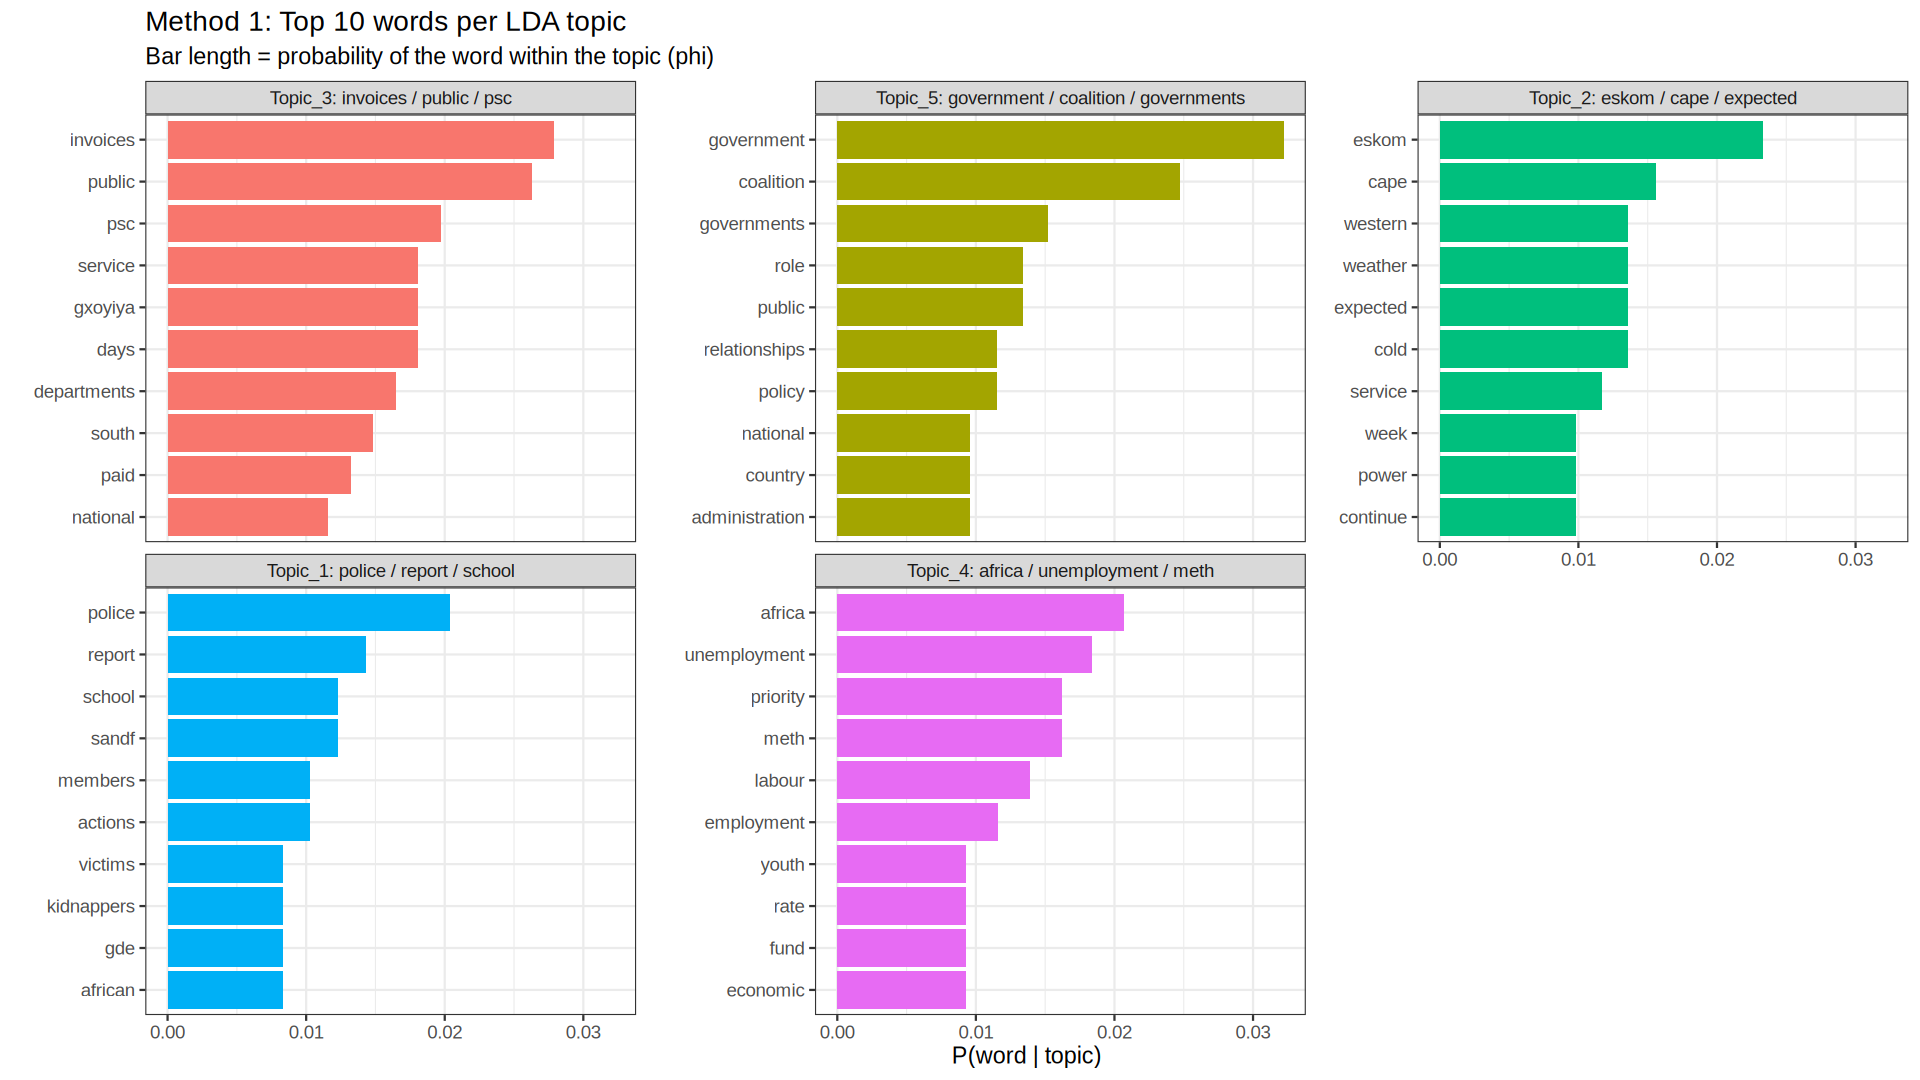

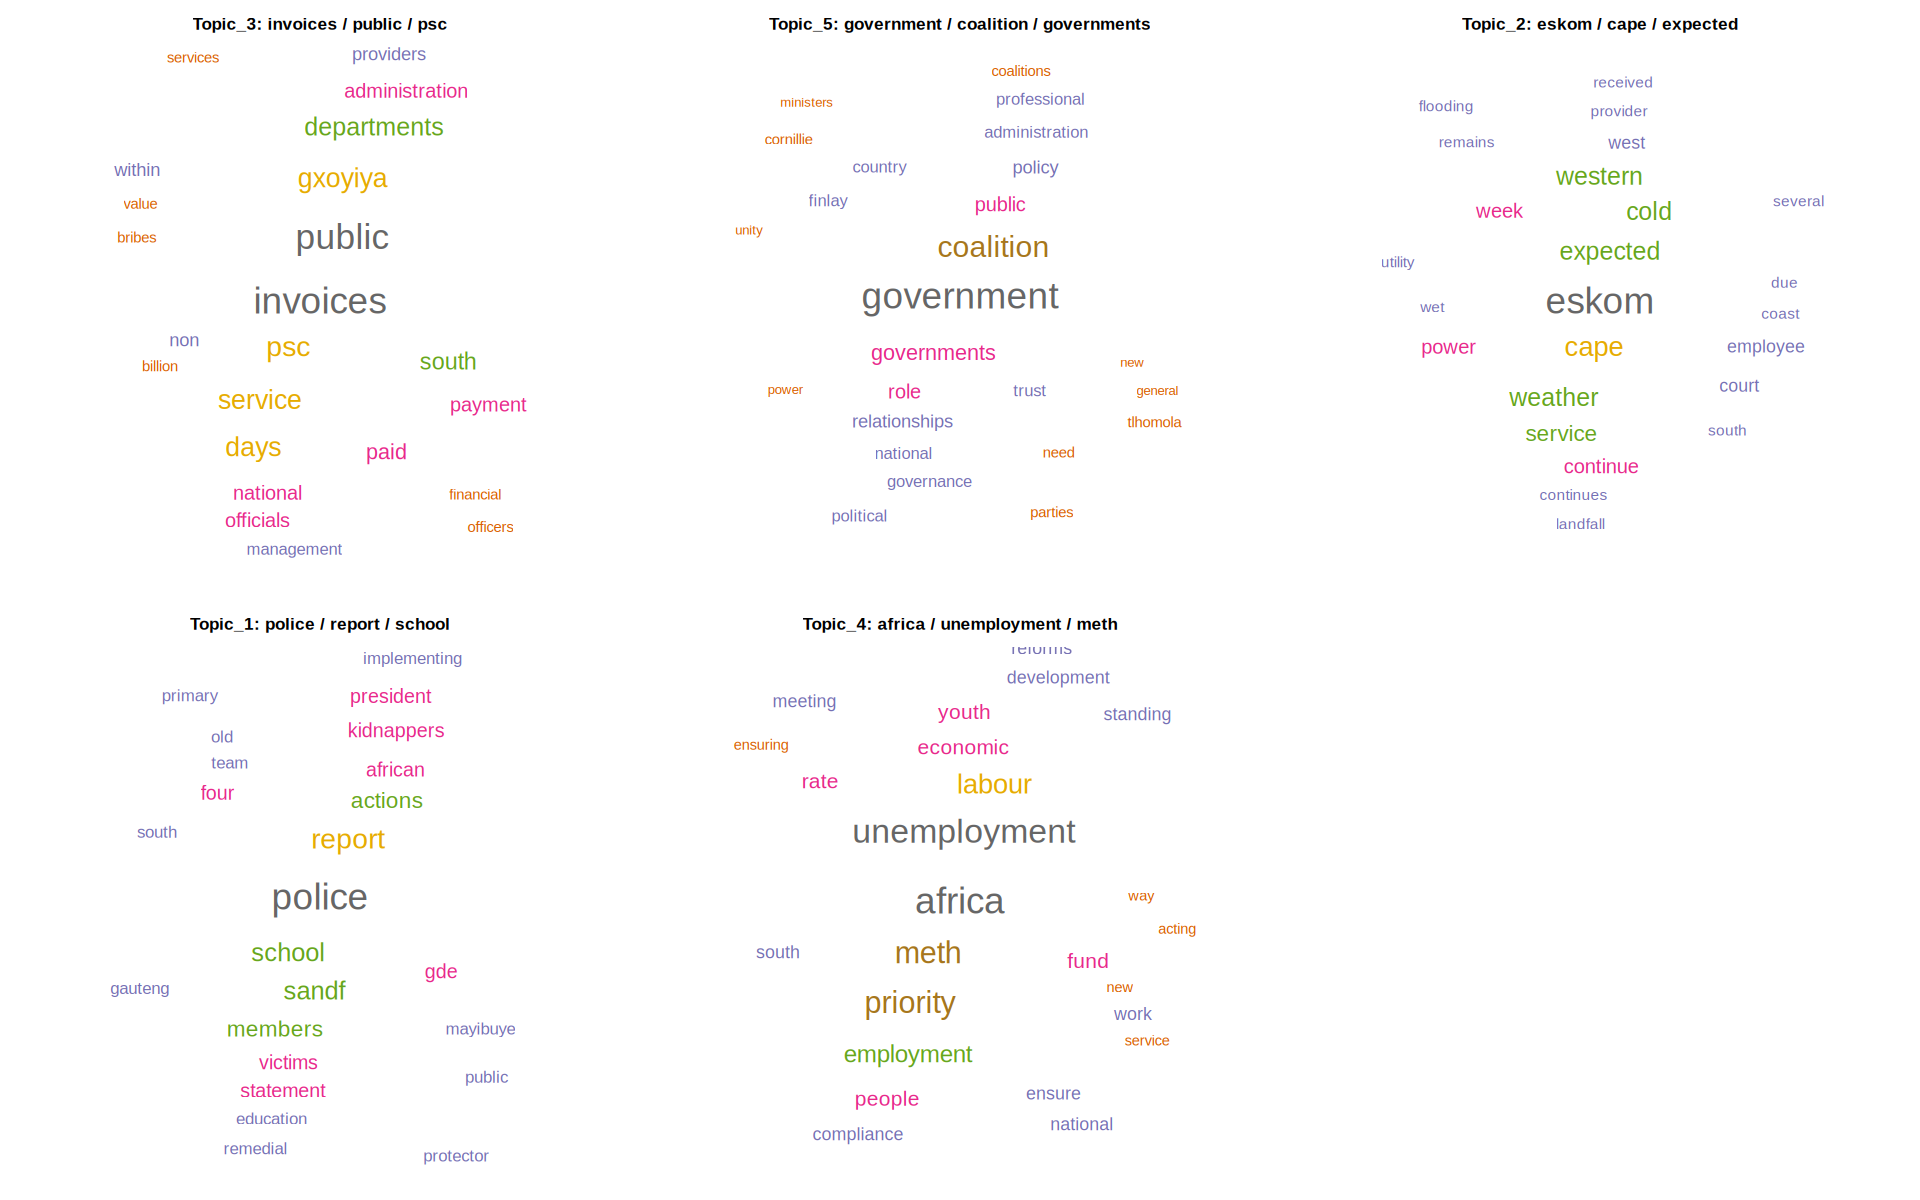

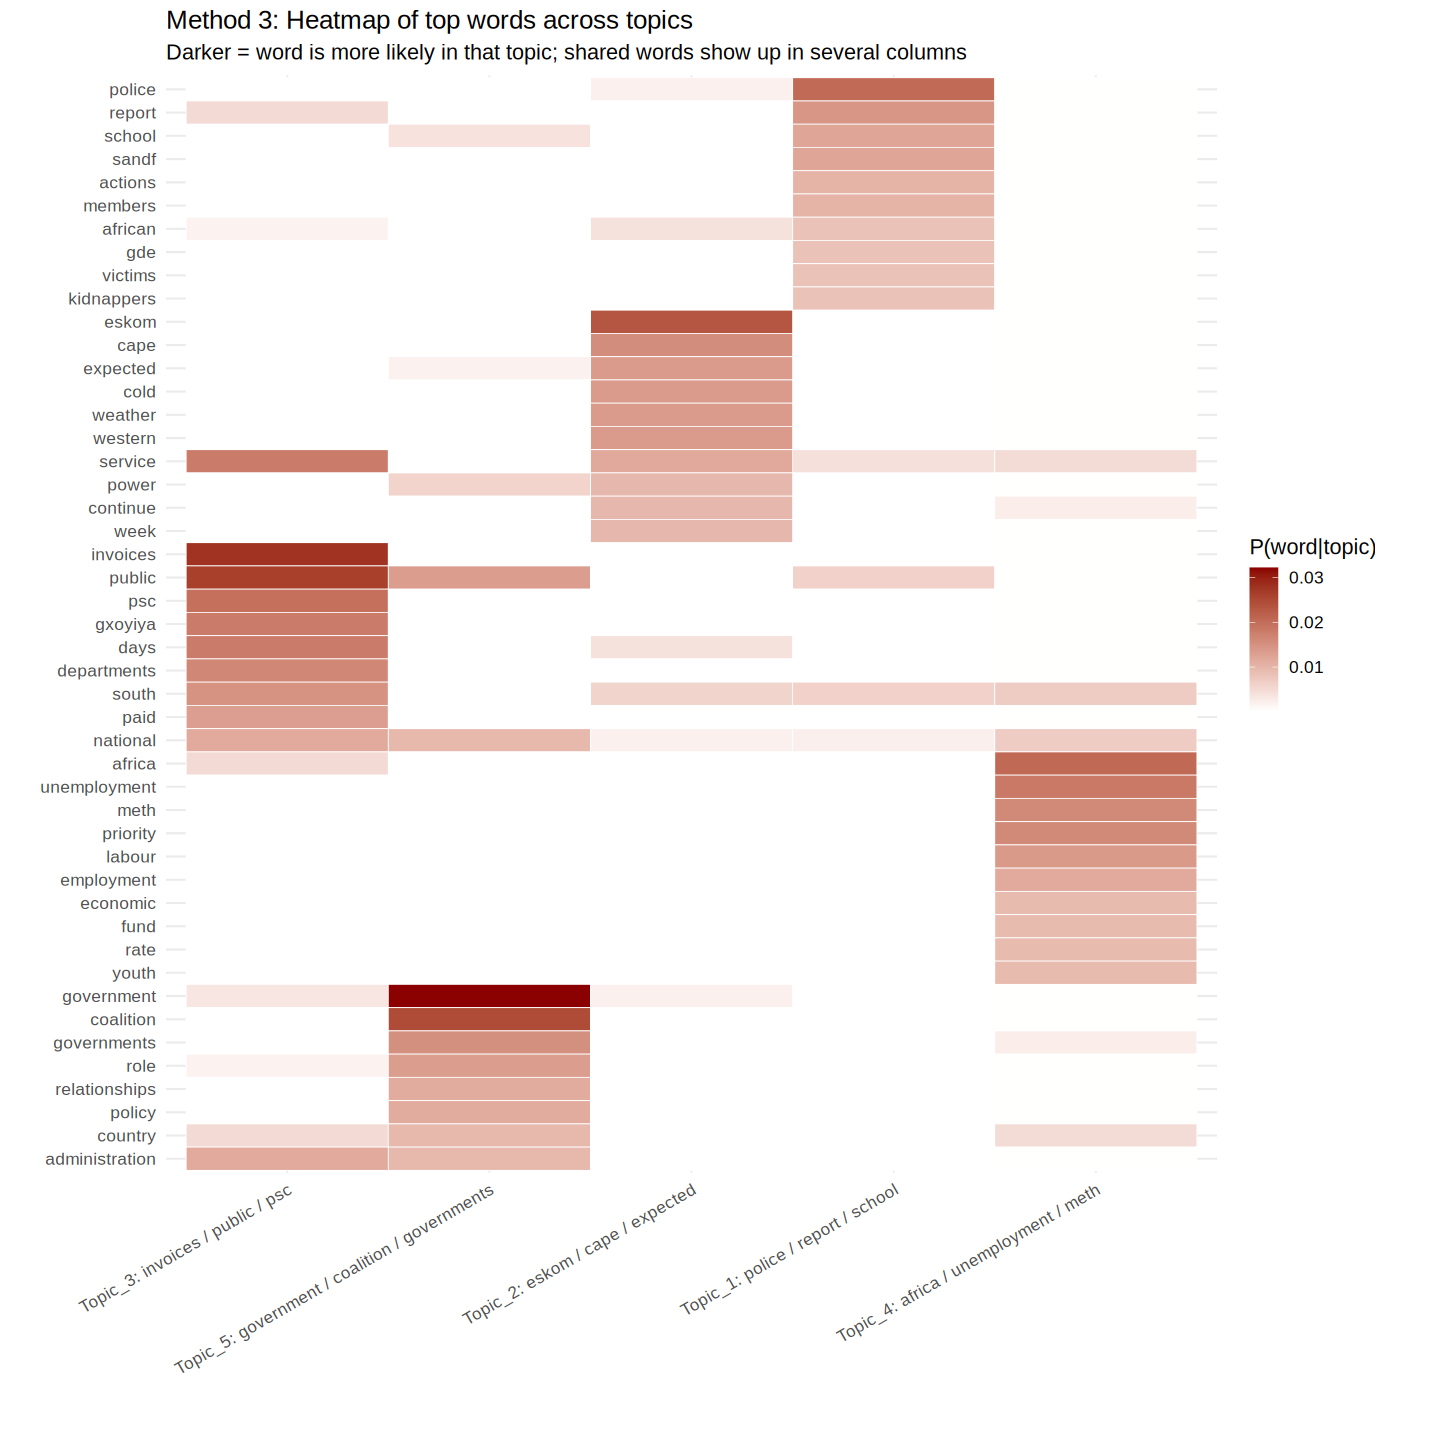

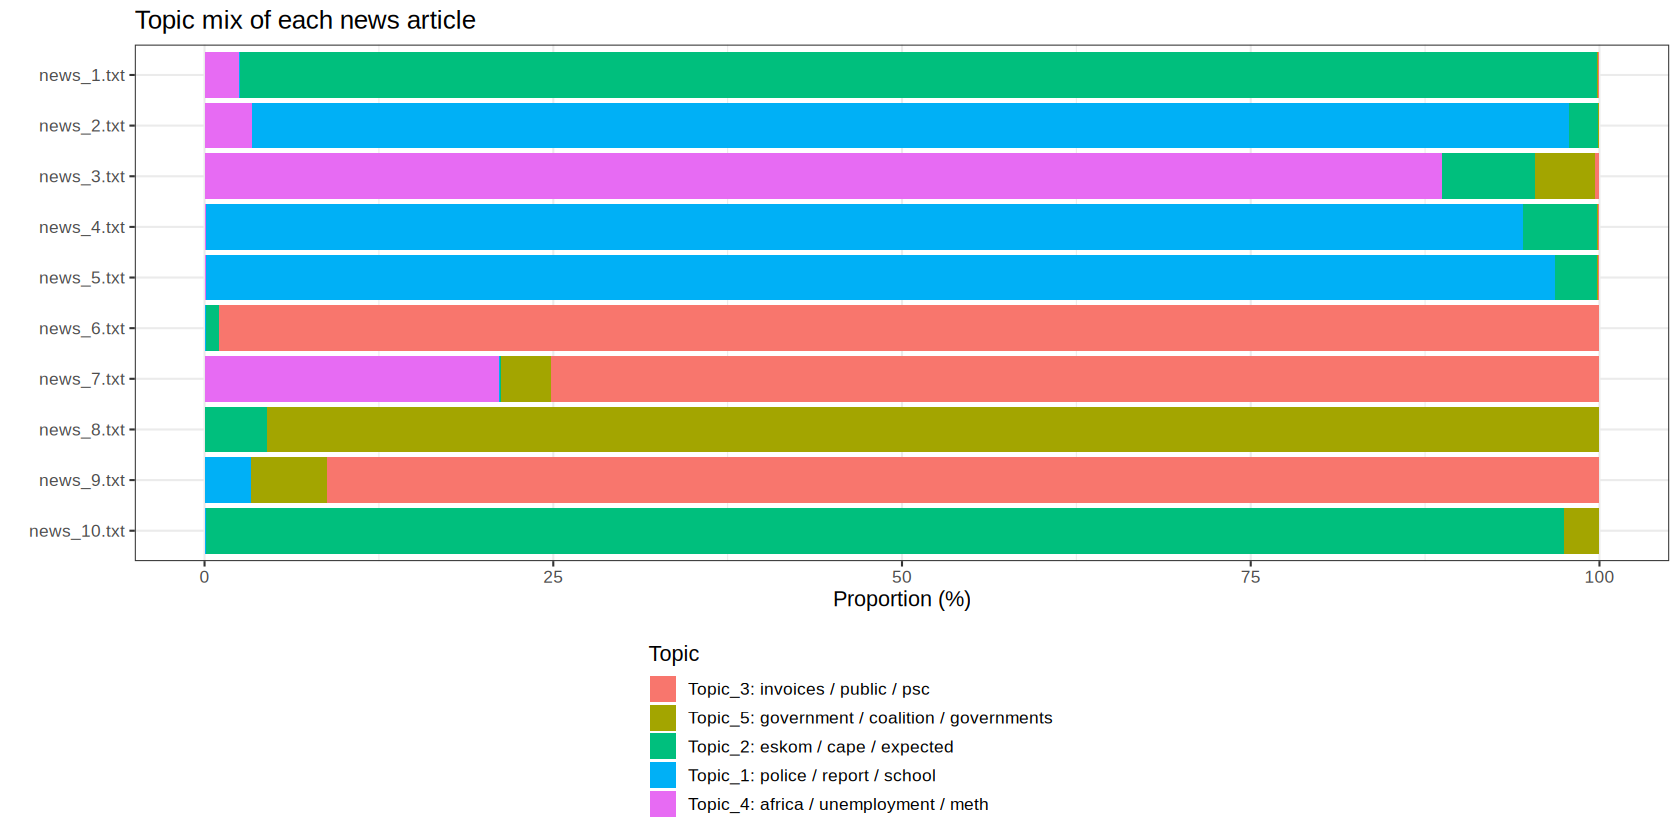

In [14]:

topic_names <- setNames(paste0(rownames(phi), ": ", topic_labels[rownames(phi)]), rownames(phi))
plot_df <- top_terms
plot_df$topic_name    <- factor(topic_names[plot_df$topic], levels = topic_names[topic_order])
plot_df$word_in_topic <- paste(plot_df$word, plot_df$topic, sep = "___")


options(repr.plot.width = 16, repr.plot.height = 9)
q2_bar <- ggplot(plot_df, aes(x = reorder(word_in_topic, probability), y = probability, fill = topic_name)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  facet_wrap(~ topic_name, scales = "free_y", ncol = 3) +
  scale_x_discrete(labels = function(x) sub("___.*$", "", x)) +
  labs(title = paste("Method 1: Top", K_WORDS, "words per LDA topic"),
       subtitle = "Bar length = probability of the word within the topic (phi)",
       x = NULL, y = "P(word | topic)") +
  theme_bw(base_size = 14)
print(q2_bar)


options(repr.plot.width = 16, repr.plot.height = 10)
par(mfrow = c(ceiling(N_TOPICS / 3), min(3, N_TOPICS)), mar = c(1, 1, 3, 1))
for (t in topic_order) {
  idx <- order(phi[t, ], decreasing = TRUE)[1:max(K_WORDS, 25)]
  set.seed(1)
  suppressWarnings(
    wordcloud(words = colnames(lda_fit$topics)[idx], freq = phi[t, idx], scale = c(2.8, 0.6),
              random.order = FALSE, rot.per = 0, colors = brewer.pal(8, "Dark2"), min.freq = 0))
  title(main = topic_names[t], cex.main = 1.3)
}
par(mfrow = c(1, 1))


options(repr.plot.width = 12, repr.plot.height = 12)
heat_words <- unique(top_terms$word)
heat_df <- melt(phi[, heat_words, drop = FALSE], varnames = c("topic", "word"), value.name = "probability")
heat_df$topic <- factor(topic_names[as.character(heat_df$topic)], levels = topic_names[topic_order])
heat_df$word  <- factor(heat_df$word, levels = rev(heat_words))
q2_heat <- ggplot(heat_df, aes(x = topic, y = word, fill = probability)) +
  geom_tile(colour = "white") +
  scale_fill_gradient(low = "white", high = "darkred") +
  labs(title = "Method 3: Heatmap of top words across topics",
       subtitle = "Darker = word is more likely in that topic; shared words show up in several columns",
       x = NULL, y = NULL, fill = "P(word|topic)") +
  theme_minimal(base_size = 13) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
print(q2_heat)


options(repr.plot.width = 14, repr.plot.height = 7)
theta_df <- melt(theta, varnames = c("document", "topic"), value.name = "proportion")
theta_df$topic    <- factor(topic_names[as.character(theta_df$topic)], levels = topic_names[topic_order])
theta_df$document <- factor(theta_df$document, levels = rev(news_df$file_name))
q2_mix <- ggplot(theta_df, aes(x = document, y = proportion * 100, fill = topic)) +
  geom_col() + coord_flip() +
  labs(title = "Topic mix of each news article", x = NULL, y = "Proportion (%)", fill = "Topic") +
  theme_bw(base_size = 13) + theme(legend.position = "bottom", legend.direction = "vertical")
print(q2_mix)


## Question 3

### 3.1

In [15]:

Q3_DIR   <- file.path(OUT, "q3")
web_agent <- user_agent(sprintf("ITBDA4-14-WebTextAPI/1.0 (student proof of concept; contact: %s) R-httr", CONTACT_EMAIL))

check_robots <- function(page_url, agent) {
  parts <- httr::parse_url(page_url)
  robots_url <- paste0(parts$scheme, "://", parts$hostname,
                       ifelse(is.null(parts$port), "", paste0(":", parts$port)), "/robots.txt")
  path <- paste0("/", ifelse(is.null(parts$path), "", parts$path))
  res <- try(GET(robots_url, agent, timeout(20)), silent = TRUE)
  if (inherits(res, "try-error") || status_code(res) != 200)
    return(list(allowed = TRUE, delay = 2, robots_url = robots_url,
                note = "no robots.txt found - default polite rules applied"))
  lines <- tolower(trimws(sub("#.*$", "", strsplit(httr::content(res, "text", encoding = "UTF-8"), "\n")[[1]])))
  in_star <- FALSE; allow <- c(); disallow <- c(); delay <- 2
  for (ln in lines) {
    if (grepl("^user-agent:", ln)) in_star <- trimws(sub("^user-agent:", "", ln)) == "*"
    else if (in_star && grepl("^disallow:", ln)) disallow <- c(disallow, trimws(sub("^disallow:", "", ln)))
    else if (in_star && grepl("^allow:", ln))    allow    <- c(allow,    trimws(sub("^allow:", "", ln)))
    else if (in_star && grepl("^crawl-delay:", ln))
      delay <- min(10, max(delay, as.numeric(trimws(sub("^crawl-delay:", "", ln))), na.rm = TRUE))
  }
  disallow <- disallow[disallow != ""]
  matching <- function(rules) rules[startsWith(tolower(path), rules)]
  d <- matching(disallow); a <- matching(allow)
  ok <- length(d) == 0 || (length(a) > 0 && max(nchar(a)) >= max(nchar(d)))
  list(allowed = ok, delay = delay, robots_url = robots_url,
       note = paste(length(disallow), "Disallow rules checked for User-agent: *"))
}

robots_check <- check_robots(WEB_URL, web_agent)
cat("robots.txt:", robots_check$robots_url, "|", robots_check$note, "\n")
cat("Scraping", WEB_URL, "allowed by robots.txt?", robots_check$allowed, "\n")
if (!robots_check$allowed) stop("robots.txt disallows this page - put a different WEB_URL in Settings (0.4).")

Sys.sleep(robots_check$delay)
resp <- GET(WEB_URL, web_agent, timeout(30))
stop_for_status(resp)
cat("HTTP status:", status_code(resp), "| content type:", headers(resp)$`content-type`, "\n")
page <- read_html(httr::content(resp, "text", encoding = "UTF-8"))


junk <- paste("script, style, noscript, table, sup.reference, .mw-editsection, .navbox,",
              ".infobox, .hatnote, .reflist, .thumb, figure, nav, footer, header, .mw-empty-elt")
xml_remove(html_elements(page, junk))


for (sel in c("#mw-content-text .mw-parser-output", "article", "main", "body")) {
  main_node <- html_element(page, sel)
  if (!inherits(main_node, "xml_missing") && length(html_elements(main_node, "p")) >= 3) break
}
nodes <- html_elements(main_node, xpath = ".//h2 | .//h3 | .//p")


section <- "Introduction"; rows <- list()
for (n in nodes) {
  tag <- xml_name(n); txt <- trimws(html_text2(n))
  if (tag %in% c("h2", "h3")) { section <- txt; next }
  if (nchar(txt) > 0) rows[[length(rows) + 1]] <- data.frame(section = section, raw_text = txt)
}
web_df <- do.call(rbind, rows)
web_df$para_id <- seq_len(nrow(web_df))
web_df$n_chars <- nchar(web_df$raw_text)
web_df <- web_df[, c("para_id", "section", "raw_text", "n_chars")]

licence <- html_attr(html_element(page, "link[rel='license'], a[rel='license']"), "href")
webtext <- list(
  url        = WEB_URL,
  title      = html_text2(html_element(page, "title")),
  retrieved  = format(Sys.time(), "%Y-%m-%d %H:%M:%S %Z"),
  user_agent = web_agent$options$useragent,
  robots_ok  = robots_check$allowed,
  licence    = ifelse(is.na(licence), "check site terms", licence),
  content    = web_df)

str(webtext, max.level = 1, give.attr = FALSE)
cat("\nParagraphs per section:\n"); print(table(factor(web_df$section, levels = unique(web_df$section))))
cat("\nFirst rows of the content data frame:\n")
print(transform(head(web_df, 6), raw_text = paste0(substr(raw_text, 1, 80), "...")), row.names = FALSE)
write.csv(web_df, file.path(Q3_DIR, "webtext_raw.csv"), row.names = FALSE)

robots.txt: https://en.wikipedia.org/robots.txt | 428 Disallow rules checked for User-agent: * 
Scraping https://en.wikipedia.org/wiki/Natural_language_processing allowed by robots.txt? TRUE 
HTTP status: 200 | content type: text/html; charset=UTF-8 
List of 7
 $ url       : chr "https://en.wikipedia.org/wiki/Natural_language_processing"
 $ title     : chr "Natural language processing - Wikipedia"
 $ retrieved : chr "2026-11-13 16:24:18 UTC"
 $ user_agent: chr "ITBDA4-14-WebTextAPI/1.0 (student proof of concept; contact: your.email@example.com) R-httr"
 $ robots_ok : logi TRUE
 $ licence   : chr "https://creativecommons.org/licenses/by-sa/4.0/deed.en"
 $ content   :'data.frame':	22 obs. of  4 variables:

Paragraphs per section:

                                       Introduction 
                                                  2 
                                            History 
                                                  1 
                 Symbolic NLP (1950s – early 1990

### 3.2 Preprocessing
Preprocessing cleans text at three levels to keep summaries readable and tokens clean. Paragraph cleaning removes boilerplate sections, citation marks, quotes, dashes, URLs, email addresses, extra spaces, short fragments, and duplicate paragraphs. Sentence splitting cuts text on periods, exclamation marks, and question marks while protecting abbreviations like e.g. from false splits. Token processing applies case folding, removes possessives, numbers, and punctuation, filters out stop words from the Snowball list and filler words, and drops one to two letter fragments. Porter stemming prepares words for scoring while charts keep unstemmed words.

In [16]:

boiler_sections <- c("references", "see also", "external links", "further reading",
                     "notes", "bibliography", "sources", "citations", "contents")
web_clean <- web_df[!tolower(web_df$section) %in% boiler_sections, ]

tidy_paragraph <- function(x) {
  x <- gsub("\\[(\\d+|[a-z]|citation needed|clarification needed|when\\?|who\\?|note \\d+)\\]", "", x,
            ignore.case = TRUE)
  x <- gsub("[\\x{2018}\\x{2019}]", "'", x, perl = TRUE)
  x <- gsub("[\\x{201C}\\x{201D}]", "\"", x, perl = TRUE)
  x <- gsub("[\\x{2013}\\x{2014}]", "-", x, perl = TRUE)
  x <- gsub("(https?://|www\\.)\\S+", "", x)
  x <- gsub("\\S+@\\S+\\.\\S+", "", x)
  trimws(gsub("\\s+", " ", x))
}
web_clean$text <- tidy_paragraph(web_clean$raw_text)
web_clean <- web_clean[nchar(web_clean$text) >= 60, ]
web_clean <- web_clean[!duplicated(tolower(web_clean$text)), ]


protect_abbr <- function(x) {
  abbr <- c("e\\.g\\.", "i\\.e\\.", "etc\\.", "vs\\.", "cf\\.", "al\\.", "Dr\\.", "Mr\\.", "Ms\\.",
            "U\\.S\\.", "U\\.K\\.", "No\\.", "Fig\\.", "approx\\.")
  for (a in abbr) x <- gsub(paste0("\\b", a), gsub("\\\\\\.", "<DOT>", a), x)
  x
}
split_sentences <- function(x) {
  s <- unlist(strsplit(protect_abbr(x), "(?<=[.!?])\\s+(?=[A-Z0-9\"])", perl = TRUE))
  trimws(gsub("<DOT>", ".", s, fixed = TRUE))
}
sentences <- do.call(rbind, lapply(seq_len(nrow(web_clean)), function(i)
  data.frame(para_id = web_clean$para_id[i], section = web_clean$section[i],
             sentence = split_sentences(web_clean$text[i]))))
sentences <- sentences[nchar(sentences$sentence) >= 25, ]


extra_stop <- c("also", "can", "may", "used", "use", "using", "one", "two", "many", "much", "often",
                "however", "well", "first", "new", "since", "within", "known", "called",
                "e.g", "etc", "among", "including", "based", "will", "such")
clean_tokens <- function(x) {
  x <- tolower(x)
  x <- gsub("'s\\b", " ", x)
  x <- gsub("[^a-z ]", " ", x)
  x <- removeWords(x, c(stopwords("english"), extra_stop))
  x <- gsub("\\b[a-z]{1,2}\\b", " ", x)
  trimws(stripWhitespace(x))
}
sentences$clean <- clean_tokens(sentences$sentence)
sentences <- sentences[nchar(sentences$clean) > 0, ]
sentences$stems <- sapply(strsplit(sentences$clean, " "),
                          function(w) paste(wordStem(w, language = "english"), collapse = " "))
sentences$sent_id <- seq_len(nrow(sentences))
web_tokens <- unlist(strsplit(sentences$clean, " "))

raw_words <- sum(lengths(strsplit(web_df$raw_text, "\\s+")))
cat("Paragraphs:", nrow(web_df), "->", nrow(web_clean), "\n")
cat("Sentences after segmentation:", nrow(sentences), "\n")
cat("Words:", raw_words, "raw ->", length(web_tokens), "pertinent tokens (",
    round(100 * (1 - length(web_tokens) / raw_words), 1), "% removed )\n")
cat("Vocabulary:", length(unique(web_tokens)), "unique terms |",
    length(unique(unlist(strsplit(sentences$stems, " ")))), "unique stems\n\n")
cat("Example sentence\n  ORIGINAL :", sentences$sentence[1], "\n  CLEANED  :", sentences$clean[1],
    "\n  STEMMED  :", sentences$stems[1], "\n")

Paragraphs: 22 -> 21 
Sentences after segmentation: 42 
Words: 993 raw -> 594 pertinent tokens ( 40.2 % removed )
Vocabulary: 365 unique terms | 326 unique stems

Example sentence
  ORIGINAL : Natural language processing (NLP) is the processing of natural language information by a computer. 
  CLEANED  : natural language processing nlp processing natural language information computer 
  STEMMED  : natur languag process nlp process natur languag inform comput 


### 3.3 Text summarisation – four techniques
Keyword summary finds frequent terms and two word phrases to show page content. Word frequency extractive summary uses Luhn from 1958 to score sentences with repeated words as the main message. TF IDF sentence scoring treats sentences as documents so distinctive sentences win. TextRank links sentences by word overlap, ranks them with PageRank, and selects central sentences.

In [17]:

n_summary <- min(N_SUMMARY, nrow(sentences))
N <- nrow(sentences)

# keyword summary
word_freq <- sort(table(web_tokens), decreasing = TRUE)
top_words <- head(data.frame(word = names(word_freq), freq = as.integer(word_freq)), 20)
bigrams <- unlist(lapply(strsplit(sentences$clean, " "), function(w)
  if (length(w) > 1) paste(head(w, -1), tail(w, -1)) else character(0)))
bigram_freq <- sort(table(bigrams), decreasing = TRUE)
top_bigrams <- head(data.frame(bigram = names(bigram_freq), freq = as.integer(bigram_freq)), 15)
cat("=== Technique 1: KEYWORD SUMMARY ===\nTop 10 terms:  ",
    paste0(head(top_words$word, 10), " (", head(top_words$freq, 10), ")", collapse = ", "),
    "\nTop 5 phrases: ", paste0(head(top_bigrams$bigram, 5), " (", head(top_bigrams$freq, 5), ")", collapse = ", "), "\n\n")

stem_lists <- strsplit(sentences$stems, " ")

# Luhn word frequency (normalised weights, length-adjusted)
stem_freq   <- table(unlist(stem_lists))
stem_weight <- stem_freq / max(stem_freq)
sentences$score_freq <- sapply(stem_lists, function(s) sum(stem_weight[s]) / sqrt(length(s)))

# TF-IDF with sentences as documents
tfidf <- as.matrix(DocumentTermMatrix(VCorpus(VectorSource(sentences$stems)),
                   control = list(weighting = weightTfIdf, wordLengths = c(1, Inf))))
sentences$score_tfidf <- rowSums(tfidf) / pmax(1, rowSums(tfidf > 0))^0.5

# TextRank - word-overlap similarity graph + PageRank
sim <- matrix(0, N, N)
for (i in 1:N) for (j in 1:N) if (i != j) {
  overlap <- length(intersect(stem_lists[[i]], stem_lists[[j]]))
  denom   <- log(length(stem_lists[[i]]) + 1) + log(length(stem_lists[[j]]) + 1)
  sim[i, j] <- if (denom > 0) overlap / denom else 0
}
damping <- 0.85
out_w <- rowSums(sim); out_w[out_w == 0] <- 1
tr_rank <- rep(1 / N, N)
for (it in 1:100) {
  new_rank <- (1 - damping) / N + damping * as.vector(t(sim / out_w) %*% tr_rank)
  if (max(abs(new_rank - tr_rank)) < 1e-8) break
  tr_rank <- new_rank
}
sentences$score_textrank <- tr_rank
cat("TextRank converged after", it, "iterations\n\n")


make_summary <- function(score_col) {
  pick <- sort(order(sentences[[score_col]], decreasing = TRUE)[1:n_summary])
  sentences[pick, c("sent_id", "section", "sentence", score_col)]
}
summaries <- list(
  "Technique 2 - Word frequency (Luhn)" = make_summary("score_freq"),
  "Technique 3 - TF-IDF scoring"         = make_summary("score_tfidf"),
  "Technique 4 - TextRank"               = make_summary("score_textrank"))

total_words <- sum(lengths(strsplit(sentences$sentence, " ")))
for (nm in names(summaries)) {
  s <- summaries[[nm]]
  summary_words <- sum(lengths(strsplit(s$sentence, " ")))
  cat("===", toupper(nm), "===\n")
  cat(paste0("  [", s$sent_id, "] ", s$sentence), sep = "\n")
  cat(sprintf("  Compression: %d of %d sentences, %d of %d words (%.1f%%)\n\n",
              nrow(s), N, summary_words, total_words, 100 * summary_words / total_words))
}

picked <- lapply(summaries, function(s) s$sent_id)
agree <- outer(seq_along(picked), seq_along(picked),
               Vectorize(function(a, b) length(intersect(picked[[a]], picked[[b]]))))
dimnames(agree) <- list(c("Luhn", "TF-IDF", "TextRank"), c("Luhn", "TF-IDF", "TextRank"))
cat("Sentences shared between summaries (diagonal = summary length):\n"); print(agree)
consensus <- Reduce(intersect, picked)
cat("\nSentences chosen by ALL three techniques:",
    if (length(consensus)) paste(consensus, collapse = ", ") else "none", "\n")

=== Technique 1: KEYWORD SUMMARY ===
Top 10 terms:   language (18), nlp (17), cognitive (13), natural (13), processing (12), linguistics (9), tasks (9), approach (7), word (7), approaches (6) 
Top 5 phrases:  natural language (13), language processing (9), artificial intelligence (3), cognitive linguistics (3), machine learning (3) 

TextRank converged after 19 iterations

=== TECHNIQUE 2 - WORD FREQUENCY (LUHN) ===
  [1] Natural language processing (NLP) is the processing of natural language information by a computer.
  [4] Major processing tasks in an NLP system include: speech recognition, text classification, natural language understanding, and natural language generation.
  [10] Starting in the late 1980s, however, there was a revolution in natural language processing with the introduction of machine learning algorithms for language processing.
  [30] However, some written languages like Chinese, Japanese and Thai do not mark word boundaries in such a fashion, and in those languag

### 3.3 (B) Visualisations


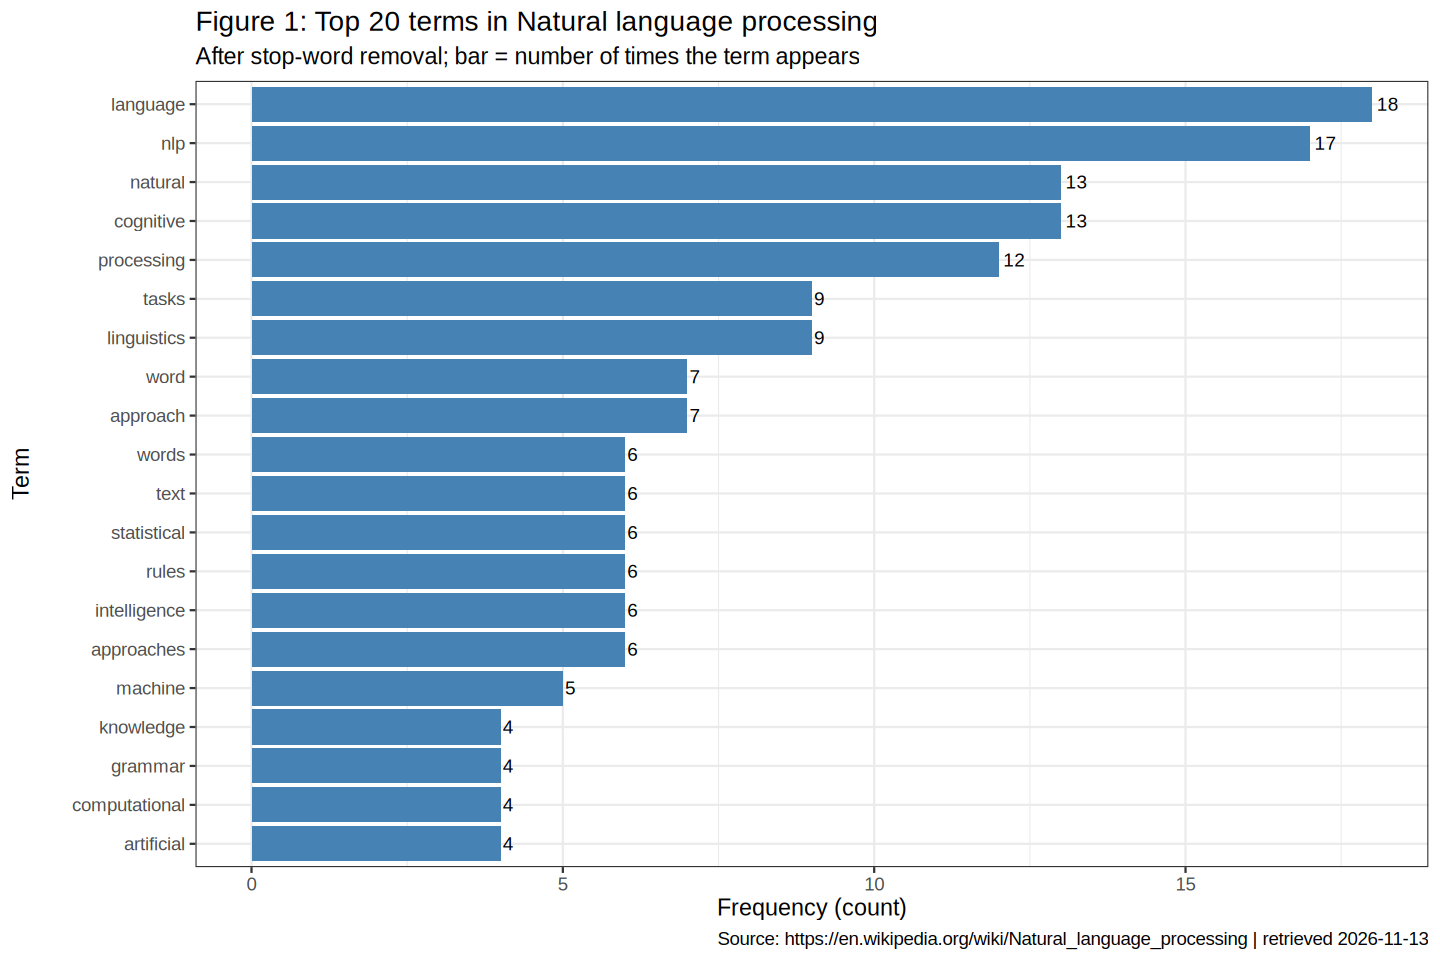

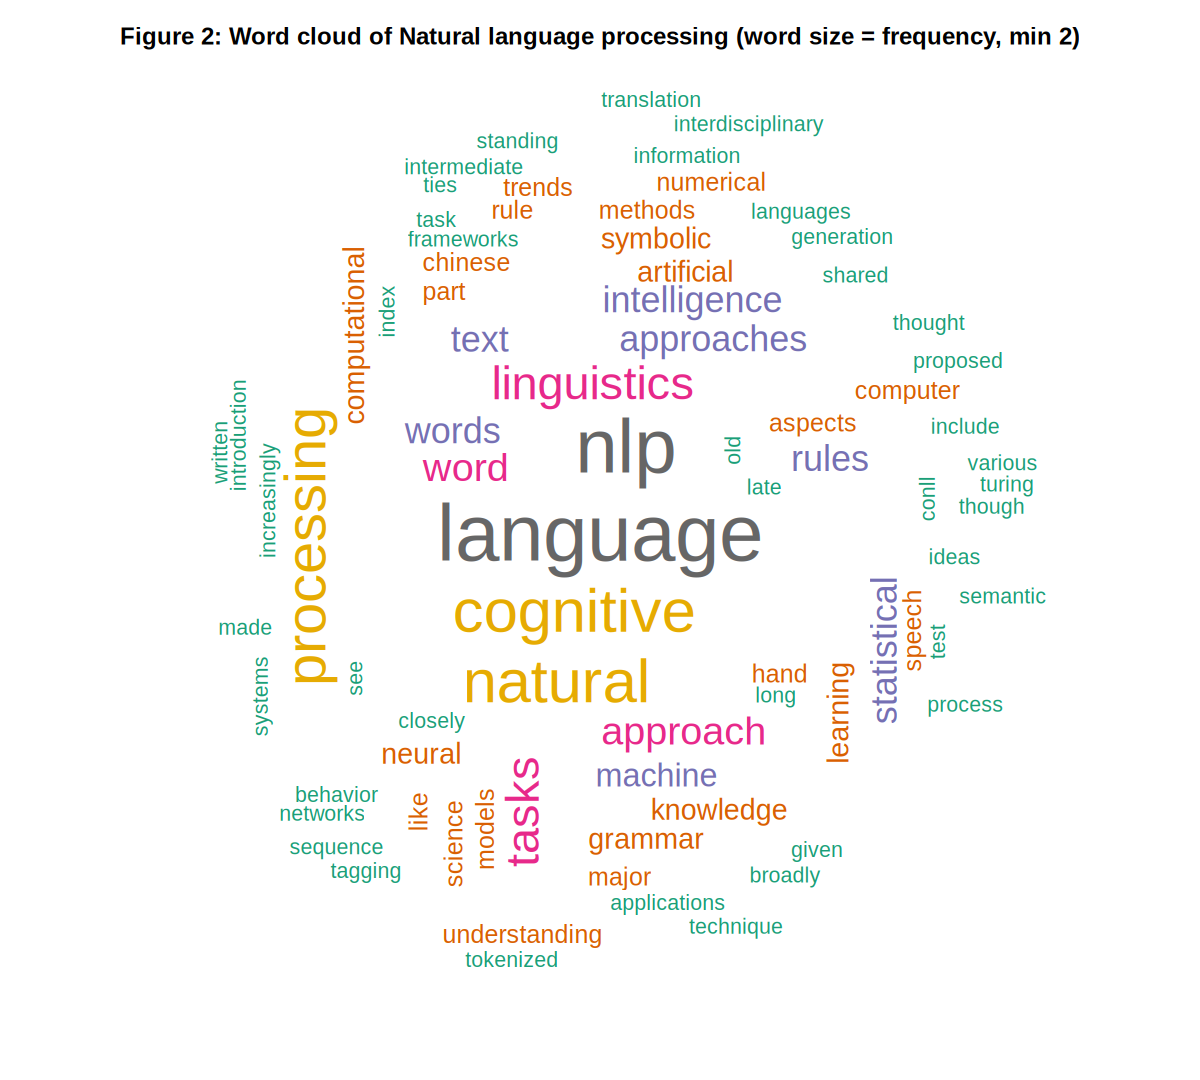

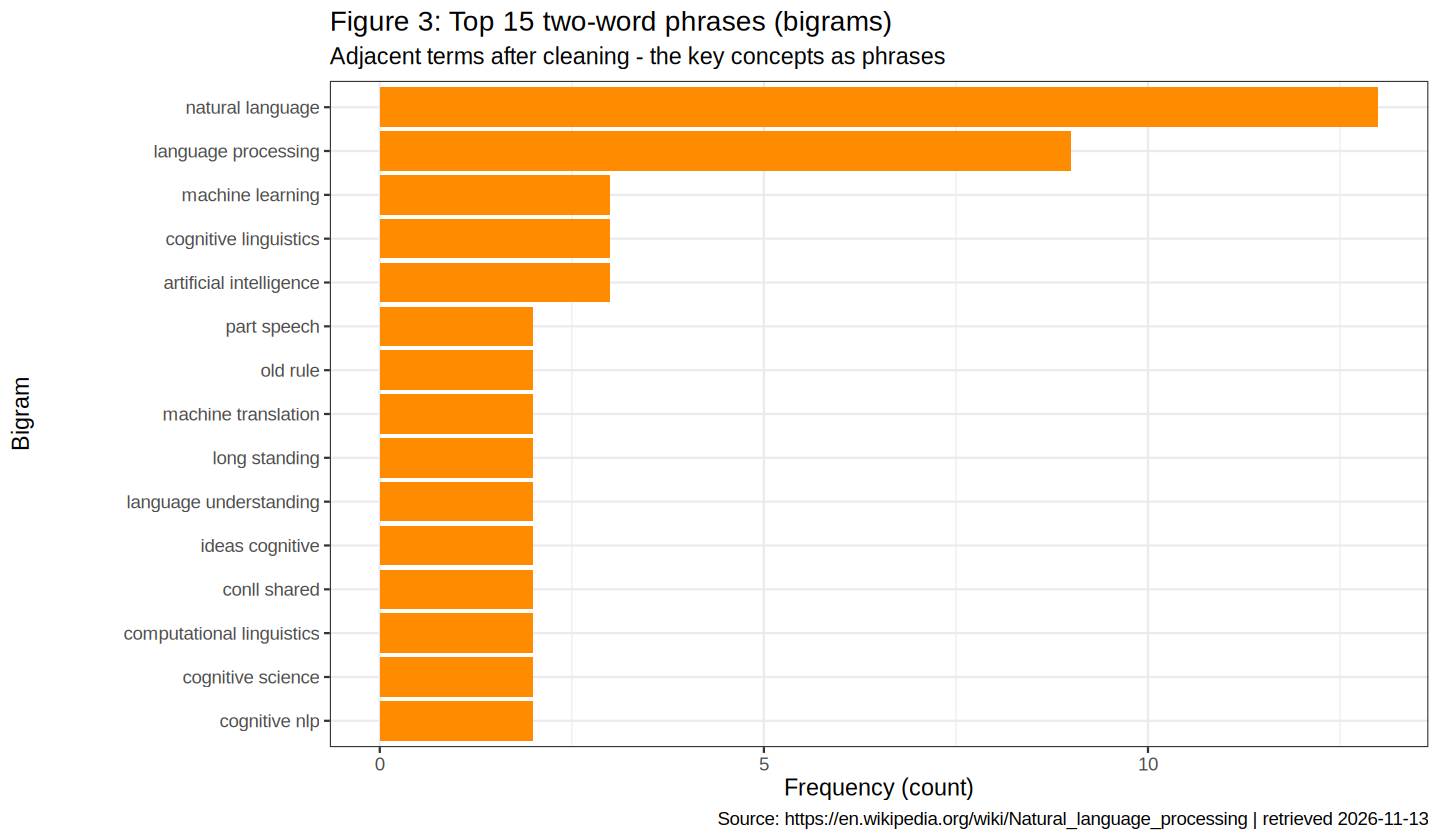

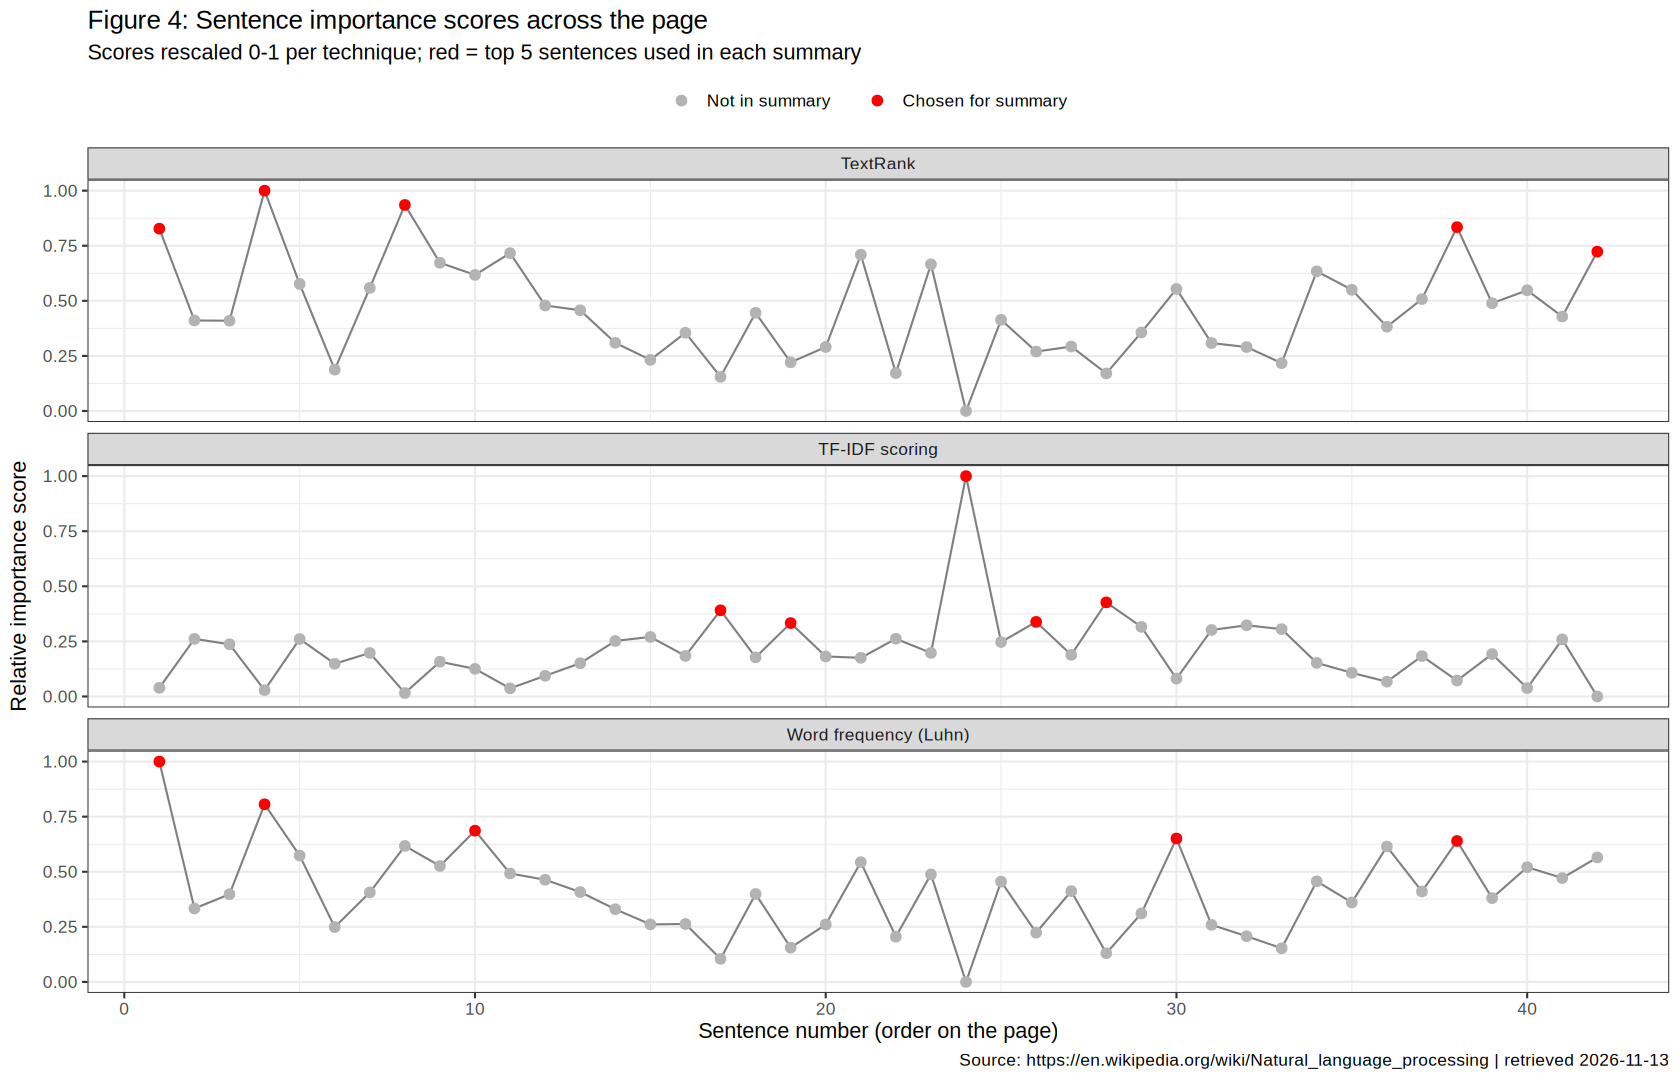

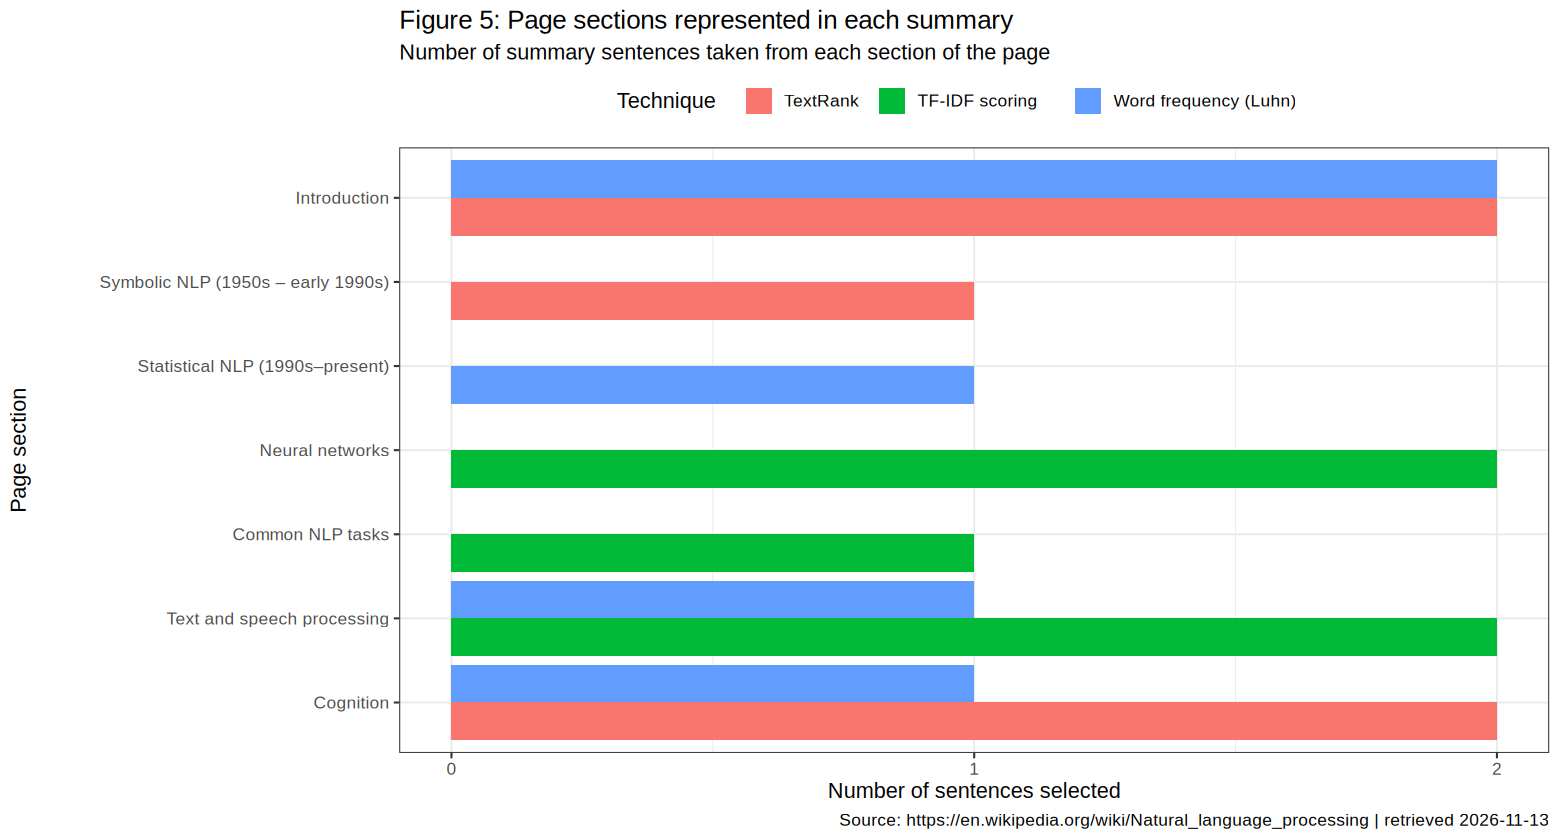

In [18]:

page_title <- sub(" - Wikipedia$", "", webtext$title)
src <- paste("Source:", webtext$url, "| retrieved", substr(webtext$retrieved, 1, 10))


options(repr.plot.width = 12, repr.plot.height = 8)
q3_terms <- ggplot(top_words, aes(x = reorder(word, freq), y = freq)) +
  geom_col(fill = "steelblue") +
  geom_text(aes(label = freq), hjust = -0.2, size = 4) +
  coord_flip() +
  labs(title = paste("Figure 1: Top 20 terms in", page_title),
       subtitle = "After stop-word removal; bar = number of times the term appears",
       x = "Term", y = "Frequency (count)", caption = src) +
  theme_bw(base_size = 14)
print(q3_terms)


options(repr.plot.width = 10, repr.plot.height = 9)
par(mar = c(0, 0, 3, 0))
set.seed(42)
suppressWarnings(
  wordcloud(names(word_freq), as.integer(word_freq), max.words = 80, min.freq = 2,
            random.order = FALSE, rot.per = 0.15, scale = c(4, 0.7), colors = brewer.pal(8, "Dark2")))
title(main = paste("Figure 2: Word cloud of", page_title, "(word size = frequency, min 2)"), cex.main = 1.2)


options(repr.plot.width = 12, repr.plot.height = 7)
q3_bigrams <- ggplot(top_bigrams, aes(x = reorder(bigram, freq), y = freq)) +
  geom_col(fill = "darkorange") +
  coord_flip() +
  labs(title = "Figure 3: Top 15 two-word phrases (bigrams)",
       subtitle = "Adjacent terms after cleaning - the key concepts as phrases",
       x = "Bigram", y = "Frequency (count)", caption = src) +
  theme_bw(base_size = 14)
print(q3_bigrams)


options(repr.plot.width = 14, repr.plot.height = 9)
rescale01 <- function(v) (v - min(v)) / max(1e-12, max(v) - min(v))
method_cols <- c("Word frequency (Luhn)" = "score_freq", "TF-IDF scoring" = "score_tfidf", "TextRank" = "score_textrank")
score_long <- do.call(rbind, lapply(seq_along(method_cols), function(m)
  data.frame(sent_id  = sentences$sent_id,
             method   = names(method_cols)[m],
             score    = rescale01(sentences[[method_cols[m]]]),
             selected = sentences$sent_id %in% picked[[m]])))
q3_scores <- ggplot(score_long, aes(x = sent_id, y = score)) +
  geom_line(colour = "grey50") +
  geom_point(aes(colour = selected), size = 2.5) +
  scale_colour_manual(values = c(`FALSE` = "grey70", `TRUE` = "red"),
                      labels = c("Not in summary", "Chosen for summary"), name = NULL) +
  facet_wrap(~ method, ncol = 1) +
  labs(title = "Figure 4: Sentence importance scores across the page",
       subtitle = paste("Scores rescaled 0-1 per technique; red = top", n_summary, "sentences used in each summary"),
       x = "Sentence number (order on the page)", y = "Relative importance score", caption = src) +
  theme_bw(base_size = 13) + theme(legend.position = "top")
print(q3_scores)

# Figure 5: sections each summary draws from
options(repr.plot.width = 13, repr.plot.height = 7)
cover <- do.call(rbind, lapply(names(summaries), function(nm)
  data.frame(method = sub("Technique \\d - ", "", nm), section = summaries[[nm]]$section)))
cover$section <- factor(cover$section, levels = rev(unique(sentences$section)))
q3_sections <- ggplot(cover, aes(x = section, fill = method)) +
  geom_bar(position = position_dodge(preserve = "single")) +
  scale_y_continuous(breaks = function(l) seq(0, ceiling(l[2]), 1)) +
  coord_flip() +
  labs(title = "Figure 5: Page sections represented in each summary",
       subtitle = "Number of summary sentences taken from each section of the page",
       x = "Page section", y = "Number of sentences selected", fill = "Technique", caption = src) +
  theme_bw(base_size = 13) + theme(legend.position = "top")
print(q3_sections)

---
## Question 4
### 4.1 Extract: web scraping + regex
The scraper respects Hacker News robots text rules by checking disallow entries and waiting thirty seconds between pages. It collects two front pages yielding about sixty posts and keeps every field as raw text. Regular expressions pull points, comment counts, inferred age in hours from hours ago strings, post types, title tags, and years from unstructured subtext lines. Data remains deliberately messy because job ads lack points, comment counts occasionally say discuss, self posts lack source sites, sliding posts create duplicates, and some links are relative. An initial raw copy saves before cleaning according to textbook guidelines.

In [19]:
# 4.1
Q4_DIR   <- file.path(OUT, "q4")
hn_base  <- "https://news.ycombinator.com"
hn_pages <- c("/news", "/news?p=2")
hn_agent <- user_agent(sprintf("ITBDA4-14-ETL-demo/1.0 (student project; contact: %s) R-httr", CONTACT_EMAIL))


robots_txt   <- tolower(httr::content(GET(paste0(hn_base, "/robots.txt"), hn_agent, timeout(20)), "text", encoding = "UTF-8"))
robots_lines <- trimws(strsplit(robots_txt, "\n")[[1]])
disallow     <- trimws(sub("^disallow:", "", grep("^disallow:", robots_lines, value = TRUE)))
crawl_delay  <- suppressWarnings(as.numeric(sub("^crawl-delay:\\s*", "", grep("^crawl-delay:", robots_lines, value = TRUE)[1])))
if (is.na(crawl_delay)) crawl_delay <- 5
blocked  <- sapply(hn_pages, function(p) any(startsWith(p, disallow[disallow != ""])))
hn_pages <- hn_pages[!blocked]
cat("Disallow rules:", paste(disallow, collapse = "  "), "\nCrawl-delay:", crawl_delay, "seconds\n")
cat("Pages allowed:", paste(hn_pages, collapse = ", "), "\n\n")

scrape_hn_page <- function(path) {
  html <- read_html(httr::content(GET(paste0(hn_base, path), hn_agent, timeout(30)), "text", encoding = "UTF-8"))
  do.call(rbind, lapply(html_elements(html, "tr.athing"), function(r) {
    sub_td <- xml_find_first(r, "following-sibling::tr[1]//td[contains(@class,'subtext')]")
    data.frame(
      item_id     = html_attr(r, "id"),
      rank_raw    = html_text(html_element(r, "span.rank")),
      title_raw   = html_text(html_element(r, "span.titleline > a")),
      link_raw    = html_attr(html_element(r, "span.titleline > a"), "href"),
      site_raw    = html_text(html_element(r, "span.sitestr")),
      subtext_raw = if (inherits(sub_td, "xml_missing")) NA else html_text(sub_td),
      posted_raw  = html_attr(html_element(sub_td, "span.age"), "title"),
      scraped_at  = format(Sys.time(), "%Y-%m-%d %H:%M:%S"),
      page        = path,
      stringsAsFactors = FALSE)
  }))
}
raw_list <- list()
for (i in seq_along(hn_pages)) {
  if (i > 1) { cat("Waiting", crawl_delay, "s (crawl-delay)...\n"); Sys.sleep(crawl_delay) }
  raw_list[[i]] <- scrape_hn_page(hn_pages[i])
  cat("Scraped", nrow(raw_list[[i]]), "posts from", hn_pages[i], "\n")
}
hn_raw <- do.call(rbind, raw_list)


first_group <- function(x, pattern, ...) {
  m <- regmatches(x, regexec(pattern, x, perl = TRUE, ...))
  sapply(m, function(v) if (length(v) > 1) v[2] else NA)
}
sub_norm <- gsub("\\x{00A0}", " ", hn_raw$subtext_raw, perl = TRUE)          # &nbsp; -> space

hn_raw$points       <- as.numeric(first_group(sub_norm, "(\\d+)\\s+points?"))
hn_raw$comments     <- as.numeric(first_group(sub_norm, "(\\d+)\\s+comments?"))
hn_raw$says_discuss <- grepl("\\bdiscuss\\b", sub_norm)
hn_raw$author       <- first_group(sub_norm, "by\\s+(\\S+)")
age_n    <- as.numeric(first_group(sub_norm, "(\\d+)\\s+(?:minute|hour|day|month|year)s?\\s+ago"))
age_unit <- first_group(sub_norm, "\\d+\\s+(minute|hour|day|month|year)s?\\s+ago")
hn_raw$age_hours    <- age_n * c(minute = 1/60, hour = 1, day = 24, month = 730, year = 8760)[age_unit]
hn_raw$title_tag    <- tolower(first_group(hn_raw$title_raw, "\\[(pdf|video|audio|\\w+)\\]"))
hn_raw$title_year   <- as.numeric(first_group(hn_raw$title_raw, "\\((19\\d{2}|20\\d{2})\\)"))
hn_raw$post_type    <- ifelse(grepl("^\\s*Ask HN", hn_raw$title_raw), "Ask HN",
                       ifelse(grepl("^\\s*Show HN", hn_raw$title_raw), "Show HN",
                       ifelse(grepl("^\\s*Launch HN", hn_raw$title_raw), "Launch HN",
                       ifelse(is.na(hn_raw$points), "Job", "Story"))))

cat("\nRecords scraped:", nrow(hn_raw), "\n\n")
str(hn_raw[, c("item_id", "title_raw", "site_raw", "points", "comments", "age_hours", "post_type")])
cat("\n--- Data quality problems in the raw scrape ---\n")
cat("Missing points (jobs / hidden scores):", sum(is.na(hn_raw$points)), "\n")
cat("Comments shown as the word 'discuss':  ", sum(hn_raw$says_discuss), "\n")
cat("Missing comment count (no number):     ", sum(is.na(hn_raw$comments)), "\n")
cat("Missing source site (self/Ask posts):  ", sum(is.na(hn_raw$site_raw)), "\n")
cat("Duplicate item ids (post moved pages): ", sum(duplicated(hn_raw$item_id)), "\n")
cat("Titles with [tags] or (year):          ", sum(!is.na(hn_raw$title_tag) | !is.na(hn_raw$title_year)), "\n")
cat("Relative links (not full URLs):        ", sum(!grepl("^https?://", hn_raw$link_raw)), "\n\n")
print(head(hn_raw[, c("title_raw", "subtext_raw")], 5), right = FALSE)

write.csv(hn_raw, file.path(Q4_DIR, "hn_raw.csv"), row.names = FALSE)    # raw copy kept (ETLT)

Disallow rules: /collapse?  /context?  /fave?  /flag?  /hide?  /login  /logout  /r?  /reply?  /submitlink?  /vote?  /x? 
Crawl-delay: 30 seconds
Pages allowed: /news, /news?p=2 

Scraped 30 posts from /news 
Waiting 30 s (crawl-delay)...
Scraped 30 posts from /news?p=2 

Records scraped: 60 

'data.frame':	60 obs. of  7 variables:
 $ item_id  : chr  "50474959" "50485295" "50483611" "50482379" ...
 $ title_raw: chr  "Reverse Engineering My Coway Air Purifier to Ditch the Cloud" "Brazil's Caixa insurer breach exposes names and tax IDs of all 7.6M customers" "Why Zig over C for Systems Programming" "Doomsday: Friday, 13 November, A.D. 2026 (1960)" ...
 $ site_raw : chr  "scottjg.com" "mziq.com" "mtsoukalos.eu" "science.org" ...
 $ points   : num  250 28 103 311 43 ...
 $ comments : num  60 1 47 210 14 3310 38 5 338 12 ...
 $ age_hours: num  3 0.517 2 4 1 ...
 $ post_type: chr  "Story" "Story" "Story" "Story" ...

--- Data quality problems in the raw scrape ---
Missing points (jobs / hidde

### 4.2
Denoising removes duplicates, trims titles, extracts pdf tags and years into separate columns, standardises sites, makes links absolute, and parses timestamps. Rule based fixes handle logical values like converting discuss comments to zero, assigning zero comments to job ads, setting self post sites to news dot ycombinator dot com, and marking missing authors as unknown. Statistical imputation fills missing points using median values of posts of similar age while flagging every imputed value so sql excludes them. Outliers receive flags rather than deletion using the interquartile range rule because outliers represent interesting data points. Derived numbers calculate points per hour, comments per point, title length, and an ai topic flag.

In [20]:
# 4.2
hn <- hn_raw
n_start <- nrow(hn)

hn <- hn[!duplicated(hn$item_id), ]

hn$title <- gsub("\\s+", " ", trimws(hn$title_raw))
hn$title <- trimws(gsub("\\s*\\[(pdf|video|audio|\\w+)\\]\\s*", " ", hn$title, ignore.case = TRUE))
hn$title <- trimws(gsub("\\s*\\((19|20)\\d{2}\\)\\s*$", "", hn$title))
hn$title <- gsub("\\s+", " ", hn$title)

hn$site <- tolower(sub("^www\\.", "", trimws(hn$site_raw)))
hn$url  <- ifelse(grepl("^https?://", hn$link_raw), hn$link_raw,
                  paste0("https://news.ycombinator.com/", hn$link_raw))

hn$rank      <- as.integer(gsub("\\D", "", hn$rank_raw))
hn$posted_at <- sub("^(\\d{4}-\\d{2}-\\d{2})T(\\d{2}:\\d{2}:\\d{2}).*$", "\\1 \\2", hn$posted_raw)
hn$posted_at[!grepl("^\\d{4}-\\d{2}-\\d{2} ", hn$posted_at)] <- NA


hn$comments[is.na(hn$comments) & hn$says_discuss] <- 0
hn$comments[is.na(hn$comments) & hn$post_type == "Job"] <- 0
hn$site[is.na(hn$site) | hn$site == ""] <- "news.ycombinator.com"
hn$author[is.na(hn$author)] <- "unknown"


hn$age_hours[is.na(hn$age_hours)] <- median(hn$age_hours, na.rm = TRUE)
age_band <- cut(hn$age_hours, breaks = c(-Inf, 6, 24, Inf), labels = c("<6h", "6-24h", ">24h"))
hn$points_imputed <- is.na(hn$points)
for (i in which(hn$points_imputed)) {
  similar <- hn$points[!hn$points_imputed & age_band == age_band[i]]
  hn$points[i] <- if (length(similar) > 0) median(similar) else median(hn$points, na.rm = TRUE)
}
hn$comments_imputed <- is.na(hn$comments)
hn$comments[hn$comments_imputed] <- median(hn$comments, na.rm = TRUE)


iqr_q <- quantile(hn$points, c(0.25, 0.75))
hn$is_viral <- hn$points > iqr_q[2] + 1.5 * (iqr_q[2] - iqr_q[1])


hn$title_words        <- lengths(strsplit(hn$title, "\\s+"))
hn$points_per_hour    <- round(hn$points / pmax(hn$age_hours, 0.5), 2)
hn$comments_per_point <- round(hn$comments / pmax(hn$points, 1), 3)
hn$is_ai_topic        <- grepl("\\b(ai|llm|llms|gpt|openai|claude|gemini|machine learning|neural|agents?)\\b",
                               hn$title, ignore.case = TRUE)

hn_clean <- hn[, c("item_id", "rank", "title", "post_type", "site", "url", "author",
                   "points", "comments", "age_hours", "posted_at", "title_tag", "title_year",
                   "title_words", "points_per_hour", "comments_per_point", "is_ai_topic",
                   "is_viral", "points_imputed", "comments_imputed", "scraped_at")]
hn_clean$title_tag[is.na(hn_clean$title_tag)] <- "none"
hn_clean$item_id <- as.integer(hn_clean$item_id)

cat("Records:", n_start, "->", nrow(hn_clean), "(duplicates removed:", n_start - nrow(hn_clean), ")\n\n")
print(data.frame(
  check  = c("missing points", "missing comments", "missing site", "missing author", "duplicate ids"),
  before = c(sum(is.na(hn_raw$points)), sum(is.na(hn_raw$comments)), sum(is.na(hn_raw$site_raw)),
             sum(is.na(hn_raw$author)), sum(duplicated(hn_raw$item_id))),
  after  = c(sum(is.na(hn_clean$points)), sum(is.na(hn_clean$comments)), sum(is.na(hn_clean$site)),
             sum(is.na(hn_clean$author)), sum(duplicated(hn_clean$item_id)))), row.names = FALSE)
cat("\nPoints imputed:", sum(hn_clean$points_imputed), "| comments imputed:", sum(hn_clean$comments_imputed),
    "| viral outliers flagged:", sum(hn_clean$is_viral), "\n\n")
print(head(hn_clean[, c("title", "post_type", "site", "points", "comments", "age_hours", "points_imputed")], 8),
      row.names = FALSE)
print(summary(hn_clean[, c("points", "comments", "age_hours", "points_per_hour")]))

hn_csv <- file.path(Q4_DIR, "hn_clean.csv")
write.csv(hn_clean, hn_csv, row.names = FALSE, na = "")
cat("\nSaved:", hn_csv, "(", nrow(hn_clean), "rows x", ncol(hn_clean), "columns )\n")

Records: 60 -> 60 (duplicates removed: 0 )

            check before after
   missing points      0     0
 missing comments      1     0
     missing site      2     0
   missing author      0     0
    duplicate ids      0     0

Points imputed: 0 | comments imputed: 0 | viral outliers flagged: 6 

                                                                         title
                  Reverse Engineering My Coway Air Purifier to Ditch the Cloud
 Brazil's Caixa insurer breach exposes names and tax IDs of all 7.6M customers
                                        Why Zig over C for Systems Programming
                                      Doomsday: Friday, 13 November, A.D. 2026
                                  A technical vision for the Haskell ecosystem
                                                          Jensen Huang resigns
                 U.S. October PPI Rises 6.5% YoY, Highest in Nearly Four Years
                       Lonewolf 0.3 – A standalone XMPP server writ

### 4.3
The cleaned csv loads into a typed table named hn posts using item id as the primary key. Investigation one measures engagement by post type and compares artificial intelligence titles against other titles using group by aggregates with filter clauses to exclude imputed values alongside the regex derived topic flag. Investigation two determines which sources drive the front page using window functions like rank over and sum sum over along with corr functions to test what correlates with high points.

In [21]:

if (!PG_READY) {
  system("service postgresql start > /dev/null 2>&1"); Sys.sleep(3)
}
system(sprintf("chmod a+rx /content %s %s && chmod a+r %s", OUT, Q4_DIR, hn_csv))

run_sql <- function(sql, db = "hn_etl") {
  f <- file.path(Q4_DIR, "_query.sql"); writeLines(sql, f); Sys.chmod(f, "0644")
  out <- suppressWarnings(system(sprintf("su postgres -c \"psql -d %s -v ON_ERROR_STOP=1 -f %s\" 2>&1", db, f),
                                 intern = TRUE))
  cat(out, sep = "\n"); invisible(out)
}
system("su postgres -c \"dropdb --if-exists hn_etl\" > /dev/null 2>&1; su postgres -c \"createdb hn_etl\"")

run_sql(sprintf("
CREATE TABLE hn_posts (
  item_id            INTEGER PRIMARY KEY,
  rank               INTEGER,
  title              TEXT NOT NULL,
  post_type          VARCHAR(20),
  site               VARCHAR(100),
  url                TEXT,
  author             VARCHAR(50),
  points             NUMERIC,
  comments           NUMERIC,
  age_hours          NUMERIC,
  posted_at          TIMESTAMP,
  title_tag          VARCHAR(20),
  title_year         INTEGER,
  title_words        INTEGER,
  points_per_hour    NUMERIC,
  comments_per_point NUMERIC,
  is_ai_topic        BOOLEAN,
  is_viral           BOOLEAN,
  points_imputed     BOOLEAN,
  comments_imputed   BOOLEAN,
  scraped_at         TIMESTAMP
);
\\copy hn_posts FROM '%s' WITH (FORMAT csv, HEADER true, NULL '')
SELECT COUNT(*) AS rows_loaded, COUNT(DISTINCT site) AS sites, SUM(points_imputed::int) AS imputed_points
FROM hn_posts;
", hn_csv))

# Investigation 1 - which kinds of post earn the most engagement?
sql_1 <- "
SELECT post_type,
       COUNT(*)                                                    AS posts,
       ROUND(AVG(points)   FILTER (WHERE NOT points_imputed), 1)   AS avg_points,
       ROUND(AVG(comments) FILTER (WHERE NOT comments_imputed), 1) AS avg_comments,
       ROUND(AVG(points_per_hour), 1)                              AS avg_points_per_hour,
       ROUND(AVG(comments_per_point), 2)                           AS comments_per_point,
       SUM(is_viral::int)                                          AS viral_posts
FROM hn_posts
GROUP BY post_type
ORDER BY avg_points DESC NULLS LAST;

SELECT CASE WHEN is_ai_topic THEN 'AI-related title' ELSE 'Other title' END AS topic,
       COUNT(*) AS posts,
       ROUND(AVG(points) FILTER (WHERE NOT points_imputed), 1) AS avg_points,
       ROUND(AVG(comments), 1) AS avg_comments
FROM hn_posts
GROUP BY 1;
"
cat("\n========== INVESTIGATION 1: engagement by post type and topic ==========\n")
run_sql(sql_1)

# Investigation 2 - which sources drive the front page?
sql_2 <- "
SELECT site,
       COUNT(*)                                                 AS posts,
       SUM(points)                                              AS total_points,
       ROUND(AVG(points), 1)                                    AS avg_points,
       RANK() OVER (ORDER BY SUM(points) DESC)                  AS points_rank,
       ROUND(100.0 * SUM(points) / SUM(SUM(points)) OVER (), 1) AS pct_of_all_points
FROM hn_posts
WHERE NOT points_imputed
GROUP BY site
ORDER BY points_rank
LIMIT 10;

SELECT ROUND(CORR(points, comments)::numeric, 3)    AS corr_points_comments,
       ROUND(CORR(points, age_hours)::numeric, 3)   AS corr_points_age,
       ROUND(CORR(points, title_words)::numeric, 3) AS corr_points_title_length
FROM hn_posts
WHERE NOT points_imputed;
"
cat("\n========== INVESTIGATION 2: top sources + what goes with high points ==========\n")
run_sql(sql_2)

writeLines(c("-- hn_etl analysis queries (ITBDA4-14, Q4.3)", sql_1, sql_2), file.path(Q4_DIR, "hn_analysis.sql"))

CREATE TABLE
COPY 60
 rows_loaded | sites | imputed_points 
-------------+-------+----------------
          60 |    56 |              0
(1 row)


========== INVESTIGATION 1: engagement by post type and topic ==========
 post_type | posts | avg_points | avg_comments | avg_points_per_hour | comments_per_point | viral_posts 
-----------+-------+------------+--------------+---------------------+--------------------+-------------
 Story     |    55 |      320.2 |        192.8 |                30.4 |               0.45 |           6
 Show HN   |     5 |      179.0 |         53.6 |                 8.9 |               0.21 |           0
(2 rows)

      topic       | posts | avg_points | avg_comments 
------------------+-------+------------+--------------
 Other title      |    49 |      316.3 |        192.0
 AI-related title |    11 |      273.6 |        133.3
(2 rows)


========== INVESTIGATION 2: top sources + what goes with high points ==========
        site         | posts | total_points

---
## References
- EMC Education Services. 2015. *Data Science & Big Data Analytics: Discovering, Analyzing, Visualizing and Presenting Data*. Indianapolis: John Wiley & Sons.
- Krotov, V. and Silva, L. 2018. Legality and ethics of web scraping. *AMCIS 2018 Proceedings*.
- Luhn, H.P. 1958. The automatic creation of literature abstracts. *IBM Journal of Research and Development*, 2(2), pp. 159–165.
- Mihalcea, R. and Tarau, P. 2004. TextRank: Bringing order into text. *Proceedings of EMNLP 2004*, pp. 404–411.